# Predicting CONMEBOL World Cup qualifier scores

**DA380A Machine Learning · HT2026 · Group 28** — Lawrence Arciniegas, Gunnar Arias

**Goal:** predict the **home score and the away score** of international football matches from information known *before* kick-off, and evaluate the predictions on the **CONMEBOL World Cup qualifiers** of the 2026 cycle (the 10 South American national teams, 90 matches).

**Dataset:** Mart Jürisoo, *International football results from 1872* (Kaggle `martj42/international-football-results-from-1872-to-2017`; downloaded 13 Oct 2026 from the author's GitHub mirror — see section 2).

**Algorithms:** (1) Linear Regression **implemented from scratch** with NumPy · (2) Random Forest Regressor (scikit-learn).

The notebook follows the 11-step structure of the project guidelines. It is **self-contained**: every function, class and constant it uses is defined in it, next to the step where it is first needed. It only needs the two dataset files `results.csv` and `former_names.csv` (section 2).

| Section | Step | Phase |
|---|---|---|
| 1 | Import libraries | 1 |
| 2 | Load the dataset | 1 |
| 3 | Explore the data | 1 |
| 4 | Preprocess the data (feature engineering) | 2 |
| 5 | Define features and target | 2 |
| 6 | Split into training and test sets | 4 |
| 7 | **Algorithm 1 — Linear Regression from scratch** | 3–4 |
| 8 | Algorithm 2 — Random Forest Regressor, and the choice of the final model (cross-validation) | 5 |
| 9 | Evaluate both models | 6 |
| 10 | Compare the results | 6 |
| 11 | Visualisations | 6 |

## 1. Import libraries

Libraries, and the constants that define the problem: the teams, the targets and the dates of the training and test periods.

In [1]:
import hashlib
import itertools
import json
import time
import urllib.request
from collections import defaultdict, deque
from datetime import date
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
TARGETS = ["home_score", "away_score"]
CONMEBOL = ["Argentina", "Bolivia", "Brazil", "Chile", "Colombia",
            "Ecuador", "Paraguay", "Peru", "Uruguay", "Venezuela"]
WORLD_CUP = "FIFA World Cup"
WCQ = "FIFA World Cup qualification"
TRAIN_START = pd.Timestamp("1994-01-01")
TEST_START = pd.Timestamp("2023-09-01")   # the 2026 CONMEBOL qualifiers started on 7 Sep 2023
TEST_END = pd.Timestamp("2025-09-09")     # last round of the 2026 CONMEBOL qualifiers
# Continental championship finals (the "50" level of the World Football Elo ratings)
CONTINENTAL_FINALS = ["Copa América", "UEFA Euro", "African Cup of Nations", "AFC Asian Cup",
                      "Gold Cup", "CONCACAF Championship", "Oceania Nations Cup", "Confederations Cup"]
TOURNAMENT_GROUPS = ["World Cup", "Continental final", "Qualifier / Nations League",
                     "Other tournament", "Friendly"]

# Where results are written: the project folder when the notebook runs from our repository's notebooks/ folder,
# otherwise the notebook's own folder
HERE = Path.cwd()
PROJECT_DIR = HERE.parent if HERE.name == "notebooks" else HERE
RESULTS_DIR = PROJECT_DIR / "results"

## 2. Load the dataset

The notebook needs `results.csv` and `former_names.csv` from the dataset. It looks for them in its own folder, in `data/`, in `data/raw/` and in `../data/raw/`. If they are not found, it downloads them from the dataset author's GitHub (the same files as on Kaggle). Our results are based on the version of 13 October 2026; newer versions only add matches after our test period.

`results.csv` has one row per match: date, home and away team, the final score (penalty shoot-outs not included), tournament, city, country, and whether the venue was neutral.

In [2]:
DATA_URL = "https://raw.githubusercontent.com/martj42/international_results/master/"
DATA_FILES = ["results.csv", "former_names.csv"]


def find_data_dir():
    """The first folder that contains both dataset files, or None."""
    for folder in [HERE, HERE / "data", HERE / "data" / "raw", HERE.parent / "data" / "raw"]:
        if all((folder / name).exists() for name in DATA_FILES):
            return folder
    return None


RAW_DIR = find_data_dir()
if RAW_DIR is None:
    RAW_DIR = HERE / "data" / "raw"
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    for name in DATA_FILES:
        urllib.request.urlretrieve(DATA_URL + name, RAW_DIR / name)
    print("Dataset files not found locally - downloaded them to", RAW_DIR)
print("Data folder:", RAW_DIR.name, "| files:", ", ".join(DATA_FILES))


def load_results(raw_dir=RAW_DIR):
    """results.csv as a DataFrame, sorted by date (stable, so same-day matches keep file order)."""
    df = pd.read_csv(Path(raw_dir) / "results.csv", parse_dates=["date"])
    return df.sort_values("date", kind="stable").reset_index(drop=True)

def load_former_names(raw_dir=RAW_DIR):
    return pd.read_csv(Path(raw_dir) / "former_names.csv", parse_dates=["start_date", "end_date"])

Data folder: raw | files: results.csv, former_names.csv


In [3]:
raw = load_results()
former = load_former_names()
print(raw.shape)
raw.head()

(49945, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


In [4]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 49945 entries, 0 to 49944
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   date        49945 non-null  datetime64[us]
 1   home_team   49945 non-null  str           
 2   away_team   49945 non-null  str           
 3   home_score  49945 non-null  int64         
 4   away_score  49945 non-null  int64         
 5   tournament  49945 non-null  str           
 6   city        49945 non-null  str           
 7   country     49945 non-null  str           
 8   neutral     49945 non-null  bool          
dtypes: bool(1), datetime64[us](1), int64(2), str(5)
memory usage: 3.1 MB


In [5]:
raw.describe(include="all").T

,count,unique,top,freq,mean,min,25%,50%,75%,max,std
date,49945,NaN,NaN,NaN,1994-09-03 02:29:48.575433,1872-11-30 00:00:00,1980-10-29 00:00:00,2000-10-09 00:00:00,2013-11-15 00:00:00,2026-10-06 00:00:00,NaN
home_team,49945,328,Brazil,618,NaN,NaN,NaN,NaN,NaN,NaN,NaN
away_team,49945,322,Uruguay,590,NaN,NaN,NaN,NaN,NaN,NaN,NaN
home_score,49945.0,NaN,NaN,NaN,1.756072,0.0,1.0,1.0,2.0,31.0,1.772078
away_score,49945.0,NaN,NaN,NaN,1.182701,0.0,0.0,1.0,2.0,21.0,1.40167
tournament,49945,225,Friendly,18263,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city,49945,2098,Kuala Lumpur,748,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,49945,269,United States,1595,NaN,NaN,NaN,NaN,NaN,NaN,NaN
neutral,49945,2,False,36669,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 3. Explore the data

### 3.1 Data quality

In [6]:
teams = pd.unique(raw[["home_team", "away_team"]].values.ravel())
print(f"Date range: {raw['date'].min().date()} -> {raw['date'].max().date()}")
print(f"Teams: {len(teams)} | tournaments: {raw['tournament'].nunique()}")
print(f"Missing values: {raw.isna().sum().sum()}")
print(f"Fully duplicated rows: {raw.duplicated().sum()}")
print(f"Same date + same teams: {raw.duplicated(subset=['date', 'home_team', 'away_team']).sum()}")
print(f"Negative scores: {((raw['home_score'] < 0) | (raw['away_score'] < 0)).sum()}")
raw[raw.duplicated(subset=["date", "home_team", "away_team"], keep=False)]

Date range: 1872-11-30 -> 2026-10-06
Teams: 337 | tournaments: 225
Missing values: 0


Fully duplicated rows: 0
Same date + same teams: 1
Negative scores: 0


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
9650,1974-02-17,Tahiti,New Caledonia,2,1,Friendly,Papeete,Tahiti,False
9651,1974-02-17,Tahiti,New Caledonia,1,2,Friendly,Papeete,Tahiti,False


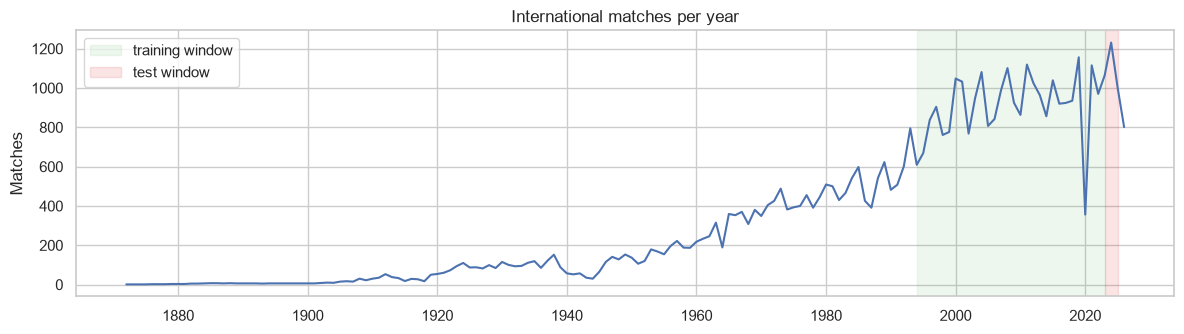

In [7]:
ax = raw.groupby(raw["date"].dt.year).size().plot(figsize=(12, 3.5))
ax.axvspan(TRAIN_START.year, TEST_START.year, color="tab:green", alpha=0.08, label="training window")
ax.axvspan(TEST_START.year, TEST_END.year, color="tab:red", alpha=0.12, label="test window")
ax.set(title="International matches per year", xlabel="", ylabel="Matches")
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

The raw data is clean in the technical sense: no missing values, no duplicated rows, no impossible scores. The one pair with the same date and teams (Tahiti vs New Caledonia, 1974) has two *different* scores, so it is most likely two real matches on the same day; it is from before our training window and is kept.

### 3.2 Cleaning: which teams and matches we keep

1. **Former team names.** `former_names.csv` lists 36 old names (e.g. Dahomey → Benin). None of them occurs in `results.csv` — the dataset already uses one name per team — so nothing has to be renamed. We keep the check so it stays visible.
2. **Only FIFA national teams.** The data also contains regional and unrecognised teams (Catalonia, Corsica, Tibet, …) from tournaments such as the Island Games or the CONIFA World Football Cup. They produce extreme results (e.g. 22–0) that have nothing to do with our problem. We keep only teams that have played at least one **World Cup or World Cup qualifier** — a simple, data-driven definition of a FIFA member.
3. **Periods.** The full history is kept, because Phase 2 needs old matches to build team ratings, but every match gets a label: *warm-up* (before 1994, features only), *train* (1994 → Aug 2023), *test* (Sep 2023 → Sep 2025, the 2026 qualifying cycle) and *after*.

In [8]:
# The cleaning steps described above
def apply_former_names(df, former):
    """Rename former team names to the current name, so a team keeps one identity over time.

    Returns (df, n_renamed). With the 13 Oct 2026 download no former name occurs in
    results.csv, so n_renamed is 0 - the function is kept so the check stays visible.
    """
    mapping = dict(zip(former["former"], former["current"]))
    renamed = df["home_team"].isin(mapping) | df["away_team"].isin(mapping)
    df = df.assign(home_team=df["home_team"].replace(mapping),
                   away_team=df["away_team"].replace(mapping))
    return df, int(renamed.sum())

def fifa_teams(df):
    """Teams that have played at least one World Cup or World Cup qualifier.

    Used as a data-driven definition of "FIFA member national team": it excludes regional and
    unrecognised teams (Catalonia, Corsica, Tibet, ...) from tournaments such as the Island
    Games or the CONIFA World Football Cup.
    """
    official = df["tournament"].isin([WORLD_CUP, WCQ])
    return set(df.loc[official, "home_team"]) | set(df.loc[official, "away_team"])

def tournament_group(tournament):
    """Map the 225 tournament names onto 5 groups of match importance."""
    t = pd.Series(tournament)
    group = pd.Series("Other tournament", index=t.index)
    group[t.str.contains("qualification") | t.str.contains("Nations League")] = "Qualifier / Nations League"
    group[t.isin(CONTINENTAL_FINALS)] = "Continental final"
    group[t == WORLD_CUP] = "World Cup"
    group[t == "Friendly"] = "Friendly"
    return pd.Categorical(group, categories=TOURNAMENT_GROUPS)

def assign_period(dates):
    period = pd.Series("after", index=dates.index)
    period[dates <= TEST_END] = "test"
    period[dates < TEST_START] = "train"
    period[dates < TRAIN_START] = "warm-up"
    return pd.Categorical(period, categories=["warm-up", "train", "test", "after"])

def clean_results(df, former=None):
    """Apply the documented cleaning. Returns (clean_df, notes)."""
    notes = [f"Loaded {len(df):,} matches, {df['date'].min().date()} -> {df['date'].max().date()}"]
    notes.append(f"Missing values: {int(df.isna().sum().sum())} | fully duplicated rows: {int(df.duplicated().sum())}")

    if former is not None:
        df, n_renamed = apply_former_names(df, former)
        notes.append(f"Matches with a former team name renamed: {n_renamed}")

    fifa = fifa_teams(df)
    all_teams = set(df["home_team"]) | set(df["away_team"])
    keep = df["home_team"].isin(fifa) & df["away_team"].isin(fifa)
    notes.append(f"Kept the {len(fifa)} teams that have played a World Cup (qualifier); "
                 f"removed {len(all_teams - fifa)} regional/unrecognised teams -> "
                 f"dropped {int((~keep).sum()):,} matches")
    df = df[keep].copy()

    df["tournament_group"] = tournament_group(df["tournament"])
    df["is_conmebol_wcq"] = ((df["tournament"] == WCQ)
                             & df["home_team"].isin(CONMEBOL) & df["away_team"].isin(CONMEBOL))
    df["period"] = assign_period(df["date"])
    df = df.reset_index(drop=True)

    counts = df["period"].value_counts().reindex(["warm-up", "train", "test", "after"])
    notes.append("Matches per period: " + ", ".join(f"{p} {n:,}" for p, n in counts.items()))
    notes.append(f"CONMEBOL World Cup qualifiers in the test period: "
                 f"{int((df['is_conmebol_wcq'] & (df['period'] == 'test')).sum())}")
    return df, notes

In [9]:
df, notes = clean_results(raw, former)
print("\n".join(notes))

Loaded 49,945 matches, 1872-11-30 -> 2026-10-06
Missing values: 0 | fully duplicated rows: 0
Matches with a former team name renamed: 0
Kept the 217 teams that have played a World Cup (qualifier); removed 120 regional/unrecognised teams -> dropped 2,565 matches
Matches per period: warm-up 18,681, train 25,266, test 2,269, after 1,164
CONMEBOL World Cup qualifiers in the test period: 90


In [10]:
removed = sorted(set(teams) - set(df["home_team"]) - set(df["away_team"]))
print(f"{len(removed)} teams removed, e.g.:", ", ".join(removed[:15]), "...")
df["period"].value_counts().reindex(["warm-up", "train", "test", "after"]).to_frame("matches")

120 teams removed, e.g.: Abkhazia, Alderney, Ambazonia, Andalusia, Arameans Suryoye, Artsakh, Asturias, Aymara, Barawa, Basque Country, Biafra, Bonaire, Brittany, Canary Islands, Canton Ticino ...


,matches
period,
warm-up,18681
train,25266
test,2269
after,1164


> **From here on, the exploration only uses the training period** (plus the warm-up history where noted). The test period — including the 90 CONMEBOL qualifiers of the 2026 cycle — is not looked at until the final evaluation, so it can't influence our choices.

In [11]:
train = df[df["period"] == "train"].copy()
train["total_goals"] = train["home_score"] + train["away_score"]
train["margin"] = train["home_score"] - train["away_score"]
print(f"Training matches: {len(train):,} | teams: {pd.unique(train[['home_team', 'away_team']].values.ravel()).size}")

Training matches: 25,266 | teams: 211


### 3.3 The targets: home and away goals

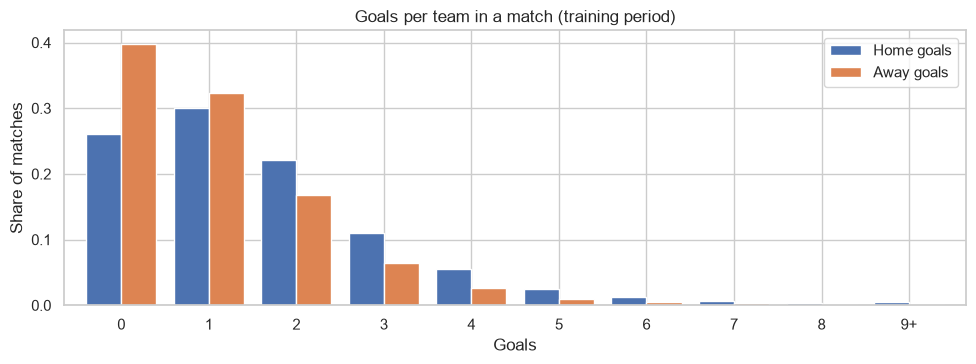

,mean,var,median,max
home_score,1.62,2.73,1.0,31.0
away_score,1.08,1.65,1.0,21.0


In [12]:
fig, ax = plt.subplots(figsize=(10, 3.8))
bins = list(range(0, 10))
labels = [str(b) for b in bins[:-1]] + ["9+"]
counts = pd.DataFrame({
    side: train[col].clip(upper=9).value_counts(normalize=True).reindex(bins, fill_value=0).values
    for side, col in [("Home goals", "home_score"), ("Away goals", "away_score")]
}, index=labels)
counts.plot(kind="bar", ax=ax, rot=0, width=0.8)
ax.set(title="Goals per team in a match (training period)", xlabel="Goals", ylabel="Share of matches")
plt.tight_layout(); plt.show()

train[TARGETS].agg(["mean", "var", "median", "max"]).T.round(2)

In [13]:
print("Matches won by 10 or more goals:", (train["margin"].abs() >= 10).sum())
train.loc[train["margin"].abs().sort_values(ascending=False).index[:5],
          ["date", "home_team", "away_team", "home_score", "away_score", "tournament"]]

Matches won by 10 or more goals: 101


,date,home_team,away_team,home_score,away_score,tournament
24397,2001-04-11,Australia,American Samoa,31,0,FIFA World Cup qualification
24395,2001-04-09,Australia,Tonga,22,0,FIFA World Cup qualification
27840,2005-03-11,Guam,North Korea,0,21,EAFF Championship
23173,2000-02-14,Kuwait,Bhutan,20,0,AFC Asian Cup qualification
24071,2000-11-24,Iran,Guam,19,0,FIFA World Cup qualification


### 3.4 Home advantage

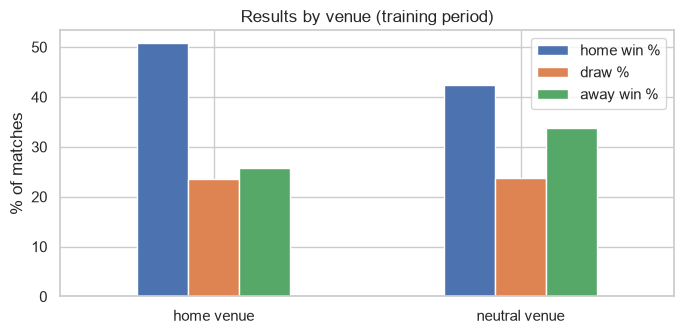

,matches,home goals,away goals,home win %,draw %,away win %
neutral,,,,,,
home venue,18703.0,1.67,1.00,50.79,23.53,25.68
neutral venue,6563.0,1.49,1.29,42.40,23.77,33.83


In [14]:
def outcome_table(d):
    return pd.Series({
        "matches": len(d),
        "home goals": d["home_score"].mean(),
        "away goals": d["away_score"].mean(),
        "home win %": 100 * (d["margin"] > 0).mean(),
        "draw %": 100 * (d["margin"] == 0).mean(),
        "away win %": 100 * (d["margin"] < 0).mean(),
    })

venue = train.groupby(train["neutral"].map({False: "home venue", True: "neutral venue"})).apply(outcome_table)
ax = venue[["home win %", "draw %", "away win %"]].plot(kind="bar", rot=0, figsize=(7, 3.5))
ax.set(title="Results by venue (training period)", xlabel="", ylabel="% of matches")
plt.tight_layout(); plt.show()
venue.round(2)

### 3.5 Match importance

In [15]:
importance = train.groupby("tournament_group", observed=True).apply(
    lambda d: pd.Series({"matches": len(d), "goals per match": d["total_goals"].mean(),
                         "mean |margin|": d["margin"].abs().mean(),
                         "home win %": 100 * (d["margin"] > 0).mean()}))
importance.round(2)

,matches,goals per match,mean |margin|,home win %
tournament_group,,,,
World Cup,500.0,2.55,1.34,44.20
Continental final,1836.0,2.64,1.49,46.68
Qualifier / Nations League,10734.0,2.85,1.84,50.47
Other tournament,3408.0,2.80,1.68,47.04
Friendly,8788.0,2.51,1.37,47.61


### 3.6 CONMEBOL World Cup qualifiers (training period)

Since the qualifiers for the 1998 World Cup, CONMEBOL plays one league: every team meets every other team home and away.

In [16]:
wcq = train[train["is_conmebol_wcq"] & (train["date"] >= "1996-01-01")].copy()
cycle_end = {1997: 1998, 2001: 2002, 2005: 2006, 2009: 2010, 2013: 2014, 2017: 2018, 2022: 2022}
wcq["cycle"] = wcq["date"].dt.year.map(lambda y: next(wc for end, wc in cycle_end.items() if y <= end))
print(wcq.groupby("cycle").size().rename("matches").to_string())
print(f"\nAll CONMEBOL qualifiers 1996-2022: {len(wcq)}")
outcome_table(wcq).round(2)

cycle
1998    72
2002    90
2006    90
2010    90
2014    72
2018    90
2022    89

All CONMEBOL qualifiers 1996-2022: 593


matches       593.00
home goals      1.67
away goals      0.95
home win %     53.96
draw %         24.28
away win %     21.75
dtype: float64

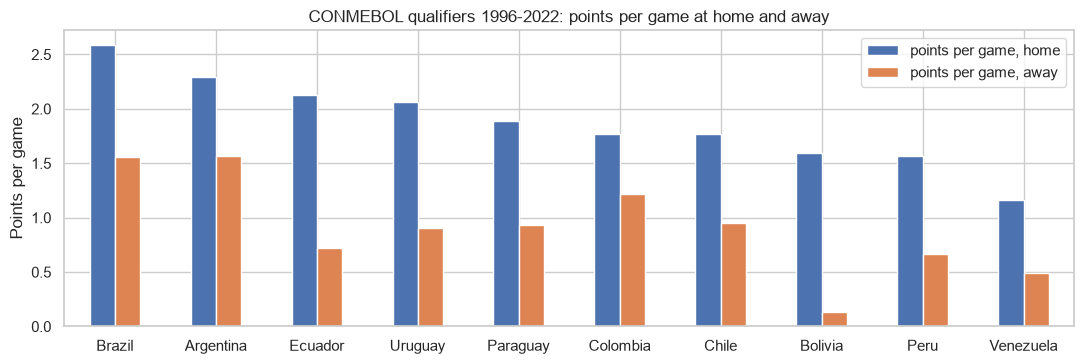

,played,"points per game, home","points per game, away",goals for per game,goals against per game
team,,,,,
Brazil,89,2.59,1.56,2.02,0.69
Argentina,121,2.30,1.57,1.64,0.86
Ecuador,122,2.13,0.72,1.34,1.23
Uruguay,122,2.07,0.90,1.37,1.22
Paraguay,122,1.89,0.93,1.19,1.30
Colombia,122,1.77,1.21,1.22,0.94
Chile,122,1.77,0.95,1.40,1.37
Bolivia,122,1.59,0.13,1.12,1.94
Peru,122,1.56,0.67,1.04,1.48


In [17]:
rows = []
for team in CONMEBOL:
    home = wcq[wcq["home_team"] == team]
    away = wcq[wcq["away_team"] == team]
    home_pts = 3 * (home["margin"] > 0) + (home["margin"] == 0)
    away_pts = 3 * (away["margin"] < 0) + (away["margin"] == 0)
    rows.append({"team": team, "played": len(home) + len(away),
                 "points per game, home": home_pts.mean(), "points per game, away": away_pts.mean(),
                 "goals for per game": (home["home_score"].sum() + away["away_score"].sum()) / (len(home) + len(away)),
                 "goals against per game": (home["away_score"].sum() + away["home_score"].sum()) / (len(home) + len(away))})
teams_wcq = pd.DataFrame(rows).set_index("team").sort_values("points per game, home", ascending=False)

ax = teams_wcq[["points per game, home", "points per game, away"]].plot(kind="bar", rot=0, figsize=(11, 3.8))
ax.set(title="CONMEBOL qualifiers 1996-2022: points per game at home and away", xlabel="", ylabel="Points per game")
plt.tight_layout(); plt.show()
teams_wcq.round(2)

### 3.7 Altitude

Bolivia plays its home qualifiers in La Paz (≈ 3,640 m) and recently El Alto (≈ 4,100 m); Ecuador mostly in Quito (≈ 2,850 m); Colombia sometimes in Bogotá (≈ 2,640 m). Do visiting teams struggle there?

In [18]:
HIGH_ALTITUDE_M = {"La Paz": 3640, "El Alto": 4100, "Quito": 2850, "Bogotá": 2640}
wcq["venue"] = np.where(wcq["city"].isin(["La Paz", "El Alto"]), "Bolivia: La Paz / El Alto",
               np.where(wcq["city"].isin(["Quito", "Bogotá"]), "Quito / Bogotá", "other venues"))
altitude = wcq.groupby("venue").apply(outcome_table)
altitude.round(2)

,matches,home goals,away goals,home win %,draw %,away win %
venue,,,,,,
Bolivia: La Paz / El Alto,61.0,1.66,1.18,42.62,31.15,26.23
Quito / Bogotá,72.0,1.54,0.72,59.72,20.83,19.44
other venues,460.0,1.69,0.95,54.57,23.91,21.52


In [19]:
# Same team, different altitude: Bolivia and Ecuador at home vs away
for team in ["Bolivia", "Ecuador"]:
    print(f"{team}: points per game at home {teams_wcq.loc[team, 'points per game, home']:.2f}, "
          f"away {teams_wcq.loc[team, 'points per game, away']:.2f}")

Bolivia: points per game at home 1.59, away 0.13
Ecuador: points per game at home 2.13, away 0.72


### 3.8 Main observations

- **Data quality.** 49,945 matches from 1872 to Oct 2026 with no missing values, no duplicated rows and no impossible scores. Removing regional and unrecognised teams dropped 2,565 matches; the training period then has **25,266 matches between 211 national teams**. The dip in 2020 is the COVID-19 pandemic.
- **The targets are small, skewed counts.** Home teams score 1.62 goals on average and away teams 1.08, with a median of 1 for both. 26% of home teams and 40% of away teams score 0. The variance (2.73 and 1.65) is larger than the mean — a long tail of big wins. 101 training matches were won by 10 or more goals (e.g. Australia 31–0 American Samoa); they are real, official matches, so we keep them, but they will push up the RMSE of every model. Team-strength features should explain most of them.
- **Home advantage is large.** At a home venue the home team scores 1.67 goals against 1.00 and wins 50.8% of the matches (away wins 25.7%). On neutral ground the gap almost disappears (1.49 vs 1.29). → `neutral` must be a feature.
- **Match importance matters.** Qualifiers have the most lopsided results (mean margin 1.84 goals, against 1.37 in friendlies), because they include mismatches between strong and very weak teams. → a match-importance feature.
- **CONMEBOL qualifiers 1996–2022:** 593 matches in 7 cycles (72 when Brazil qualified automatically for 1998 and as hosts for 2014; 89 for 2022 because Brazil vs Argentina in September 2021 was suspended). The home team wins 54.0% (draw 24.3%, away win 21.7%) and scores 1.67 goals against 0.95 — a **stronger home advantage than in international football overall**.
- **Brazil and Argentina** are the strongest teams both at home and away (2.59 / 1.56 and 2.30 / 1.57 points per game).
- **Altitude.** Bolivia takes 1.59 points per game at home but only 0.13 away; Ecuador 2.13 against 0.72 — by far the biggest home/away gaps. In Quito and Bogotá the home team wins 59.7% and visitors score only 0.72 goals per game. In La Paz / El Alto the home win rate is lower (42.6%) because Bolivia is a weaker team overall, but compared with Bolivia's away record the effect is huge. → we move the **altitude** feature from "stretch" to the planned features of Phase 2.

**What this means for Phase 2:** team strength (Elo ratings) to explain the big wins and the dominance of Brazil and Argentina, recent form, the `neutral` flag, a match-importance feature, and venue altitude.

## 4. Preprocess the data — feature engineering

The raw table only says *who* played *where* and *what the score was*. A model needs to know, **before kick-off**, how strong both teams are, how they have played recently, how they did against each other, and where the match is played. All features are built by `build_features` (code below the explanation):

| Feature | For each match | Why (from section 3) |
|---|---|---|
| `elo_home`, `elo_away` | Elo rating of both teams | Team strength — explains the big wins and the dominance of Brazil and Argentina |
| `form_gf_*`, `form_ga_*`, `form_pts_*` | Goals for, goals against and points per match over each team's last 10 matches | Current form, which ratings react to only slowly |
| `h2h_gd`, `h2h_n` | Mean goal difference (home-team view) in the last 5 meetings, and how many meetings there were | Some match-ups have a history of their own |
| `neutral` | 1 if the venue is neutral | Home advantage is ≈ 0.7 goals at a home venue and almost gone on neutral ground |
| `altitude_km` | Venue altitude for venues at 1,500 m or higher (La Paz 3.64 km, Quito 2.85 km, …), else 0 | Bolivia and Ecuador have the largest home/away gaps |
| `is_world_cup`, `is_continental_final`, `is_qualifier`, `is_other_tournament` | Tournament group (Friendly = reference) | Qualifiers have the most lopsided scores |
| `year` | Calendar year | Long-term trends in scoring |

> **The leakage rule.** Matches are processed in date order. For every match, the features are read **first**, and only **then** is the match's result added to the team statistics. So no match can see its own result or any later result. A unit test in our repository (`tests/test_features.py`) checks this: changing the score of one match must not change the features of that match or of any earlier match.

**Elo ratings** (World Football Elo method, eloratings.net). Every team starts at 1500. After each match:

$$R_\text{new} = R_\text{old} + K \cdot G \cdot (W - W_e), \qquad W_e = \frac{1}{10^{-dr/400} + 1}$$

- $W$ = 1 for a win, 0.5 for a draw, 0 for a loss; $W_e$ = the expected result, where $dr$ is the rating difference **+100 for the home team** (unless the venue is neutral).
- $K$ = match importance: 60 World Cup · 50 continental final · 40 qualifier / Nations League · 30 other tournament · 20 friendly.
- $G$ = margin of victory: 1 for 0–1 goals, 1.5 for 2 goals, $(11 + N)/8$ for $N \geq 3$.

The ratings are computed over the **whole history since 1872**, so they are already meaningful when the training period starts in 1994.

In [20]:
ELO_START = 1500.0
ELO_HOME_ADVANTAGE = 100.0
# K = weight of a match in the Elo update, by tournament group (eloratings.net levels;
# Nations League is counted with the qualifiers - our choice)
ELO_K = {"World Cup": 60, "Continental final": 50, "Qualifier / Nations League": 40,
         "Other tournament": 30, "Friendly": 20}
FORM_WINDOW = 10
H2H_WINDOW = 5
# Approximate city elevations (m) of venues at 1,500 m or higher that occur in the data.
# Keyed by (city, country) because some names exist twice (Cuenca, Guadalajara are also in Spain).
# Values are rounded city elevations (about +-50-100 m); every other venue counts as 0.
VENUE_ALTITUDE_M = {
    ("El Alto", "Bolivia"): 4090, ("Oruro", "Bolivia"): 3735, ("La Paz", "Bolivia"): 3640,
    ("Cusco", "Peru"): 3400, ("Quito", "Ecuador"): 2850, ("Sucre", "Bolivia"): 2810,
    ("Latacunga", "Ecuador"): 2750, ("Toluca", "Mexico"): 2660, ("Bogotá", "Colombia"): 2640,
    ("Ambato", "Ecuador"): 2580, ("Cochabamba", "Bolivia"): 2560, ("Cuenca", "Ecuador"): 2560,
    ("Addis Ababa", "Ethiopia"): 2355, ("Arequipa", "Peru"): 2335, ("Thimphu", "Bhutan"): 2330,
    ("Asmara", "Eritrea"): 2325, ("Sana'a", "Yemen"): 2250, ("Mexico City", "Mexico"): 2240,
    ("Manizales", "Colombia"): 2150, ("Puebla", "Mexico"): 2135, ("Tarija", "Bolivia"): 1850,
    ("Nairobi", "Kenya"): 1795, ("Kabul", "Afghanistan"): 1790, ("Johannesburg", "South Africa"): 1753,
    ("Kigali", "Rwanda"): 1567, ("Guadalajara", "Mexico"): 1566,
}
IMPORTANCE_DUMMIES = {"World Cup": "is_world_cup", "Continental final": "is_continental_final",
                      "Qualifier / Nations League": "is_qualifier", "Other tournament": "is_other_tournament"}
# The feature columns used by the models (all numeric). Note: no elo_diff - it would be an exact
# linear combination of elo_home and elo_away, which makes the normal equation singular.
FEATURES = (["elo_home", "elo_away",
             "form_gf_home", "form_ga_home", "form_pts_home",
             "form_gf_away", "form_ga_away", "form_pts_away",
             "h2h_gd", "h2h_n", "neutral", "altitude_km"]
            + list(IMPORTANCE_DUMMIES.values()) + ["year"])

def goal_multiplier(margin):
    """Elo G factor: 1 for a margin of 0-1 goals, 1.5 for 2 goals, (11 + N) / 8 for N >= 3."""
    margin = abs(margin)
    if margin <= 1:
        return 1.0
    if margin == 2:
        return 1.5
    return (11 + margin) / 8

def expected_home_result(elo_home, elo_away, neutral):
    """Elo expectation for the home team (1 = sure win, 0.5 = even), incl. home advantage."""
    dr = elo_home - elo_away + (0.0 if neutral else ELO_HOME_ADVANTAGE)
    return 1.0 / (10 ** (-dr / 400) + 1)

def elo_update(elo_home, elo_away, home_score, away_score, neutral, k):
    """Return the new (elo_home, elo_away) after one match. The update is zero-sum."""
    result = 1.0 if home_score > away_score else 0.5 if home_score == away_score else 0.0
    change = k * goal_multiplier(home_score - away_score) * (result - expected_home_result(elo_home, elo_away, neutral))
    return elo_home + change, elo_away - change

def build_features(df):
    """Pre-match features for every row of the cleaned, date-sorted match table `df`.

    Returns a DataFrame with the same index as `df` and the columns in FEATURES
    (plus elo_diff and n_prev_home / n_prev_away, which are kept for analysis only).
    """
    if not df["date"].is_monotonic_increasing:
        raise ValueError("matches must be sorted by date")

    elo = defaultdict(lambda: ELO_START)
    recent = defaultdict(lambda: deque(maxlen=FORM_WINDOW))      # team -> (goals for, goals against, points)
    meetings = defaultdict(lambda: deque(maxlen=H2H_WINDOW))     # (team_a, team_b) sorted -> goal difference seen by team_a
    rows = []

    for m in df[["home_team", "away_team", "home_score", "away_score", "neutral", "tournament_group"]].itertuples(index=False):
        home, away = m.home_team, m.away_team
        pair = tuple(sorted((home, away)))
        sign = 1 if pair[0] == home else -1                      # converts team_a's view to the home view

        # 1) read the features - only matches before this one have been added so far
        feats = {"elo_home": elo[home], "elo_away": elo[away]}
        for side, team in (("home", home), ("away", away)):
            hist = recent[team]
            feats[f"n_prev_{side}"] = len(hist)
            if hist:
                gf, ga, pts = np.mean(hist, axis=0)
            else:                                                 # first ever match: no form yet
                gf = ga = pts = np.nan
            feats[f"form_gf_{side}"], feats[f"form_ga_{side}"], feats[f"form_pts_{side}"] = gf, ga, pts
        past = meetings[pair]
        feats["h2h_n"] = len(past)
        feats["h2h_gd"] = sign * float(np.mean(past)) if past else 0.0
        rows.append(feats)

        # 2) add this match's result to the statistics (used by LATER matches only)
        hs, as_ = int(m.home_score), int(m.away_score)
        elo[home], elo[away] = elo_update(elo[home], elo[away], hs, as_, bool(m.neutral), ELO_K[m.tournament_group])
        home_pts, away_pts = (3, 0) if hs > as_ else (1, 1) if hs == as_ else (0, 3)
        recent[home].append((hs, as_, home_pts))
        recent[away].append((as_, hs, away_pts))
        meetings[pair].append(sign * (hs - as_))

    feat = pd.DataFrame(rows, index=df.index)
    feat["elo_diff"] = feat["elo_home"] - feat["elo_away"]
    feat["neutral"] = df["neutral"].astype(int)
    altitude_m = pd.Series([VENUE_ALTITUDE_M.get(key, 0) for key in zip(df["city"], df["country"])], index=df.index)
    feat["altitude_km"] = altitude_m / 1000
    for group, column in IMPORTANCE_DUMMIES.items():
        feat[column] = (df["tournament_group"] == group).astype(int)
    feat["year"] = df["date"].dt.year
    return feat[FEATURES + ["elo_diff", "n_prev_home", "n_prev_away"]]

In [21]:
feat = build_features(df)
data = df.drop(columns="neutral").join(feat)          # the features' 0/1 version of `neutral` is kept
print(f"Feature table: {len(feat):,} matches x {len(FEATURES)} model features (built in date order)")
data.loc[data["period"] == "train", ["date", "home_team", "away_team", "home_score", "away_score"] + FEATURES].tail(3)

Feature table: 47,380 matches x 17 model features (built in date order)


,date,home_team,away_team,home_score,away_score,elo_home,elo_away,form_gf_home,form_ga_home,form_pts_home,form_gf_away,form_ga_away,form_pts_away,h2h_gd,h2h_n,neutral,altitude_km,is_world_cup,is_continental_final,is_qualifier,is_other_tournament,year
43944,2023-08-28,Mauritius,Seychelles,1,0,1153.840867,1051.771232,0.8,1.4,1.0,0.4,1.7,0.4,1.0,5,1,0.0,0,0,0,1,2023
43945,2023-08-31,Tahiti,Cook Islands,3,0,1449.294846,1127.752568,2.5,1.5,1.3,1.0,3.0,0.7,4.8,5,0,0.0,0,0,0,0,2023
43946,2023-08-31,Madagascar,Comoros,4,2,1348.884558,1361.674846,1.0,1.5,1.0,0.9,1.4,0.9,2.0,5,0,0.0,0,0,0,1,2023


### 4.1 Do the Elo ratings make sense?

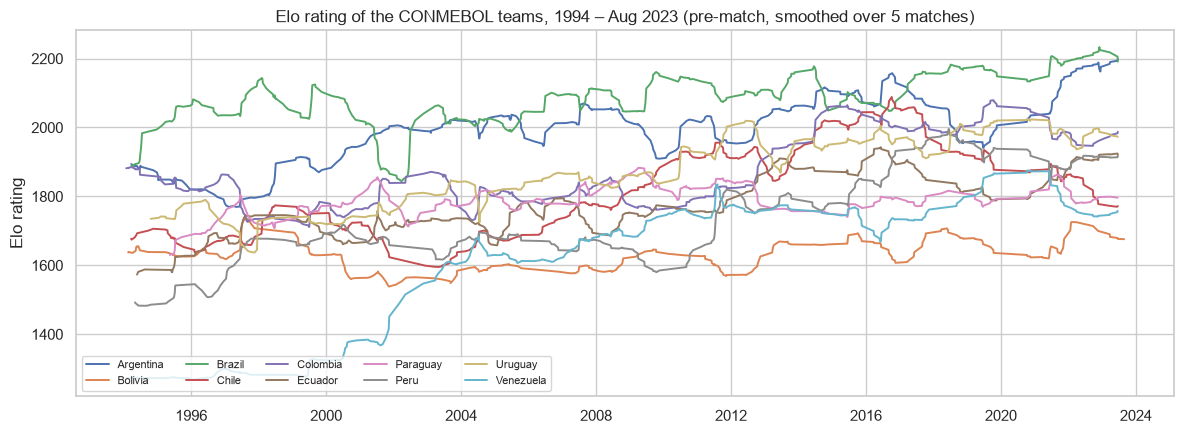

In [22]:
train_data = data[data["period"] == "train"]

# pre-match rating of every CONMEBOL team over the training period
long = pd.concat([
    train_data[["date", "home_team", "elo_home"]].set_axis(["date", "team", "elo"], axis=1),
    train_data[["date", "away_team", "elo_away"]].set_axis(["date", "team", "elo"], axis=1),
])
long = long[long["team"].isin(CONMEBOL)].sort_values("date")

fig, ax = plt.subplots(figsize=(12, 4.5))
for team, d in long.groupby("team"):
    ax.plot(d["date"], d["elo"].rolling(5, min_periods=1).mean(), label=team, lw=1.4)
ax.set(title="Elo rating of the CONMEBOL teams, 1994 – Aug 2023 (pre-match, smoothed over 5 matches)",
       xlabel="", ylabel="Elo rating")
ax.legend(ncol=5, fontsize=8, loc="lower left")
plt.tight_layout(); plt.show()

In [23]:
# each team's pre-match rating in its last training match (end of August 2023)
last_home = train_data[["date", "home_team", "elo_home"]].set_axis(["date", "team", "elo"], axis=1)
last_away = train_data[["date", "away_team", "elo_away"]].set_axis(["date", "team", "elo"], axis=1)
latest = (pd.concat([last_home, last_away]).sort_values("date", kind="stable")
            .groupby("team").tail(1).set_index("team")["elo"].sort_values(ascending=False))
print("Top 10 at the end of the training period:")
print(latest.head(10).round(0).to_string())
print("\nCONMEBOL teams:")
print(latest[CONMEBOL].sort_values(ascending=False).round(0).to_string())

Top 10 at the end of the training period:
team
Argentina      2202.0
Brazil         2180.0
France         2163.0
England        2063.0
Portugal       2062.0
Croatia        2056.0
Netherlands    2054.0
Spain          2033.0
Belgium        2026.0
Colombia       1997.0

CONMEBOL teams:
team
Argentina    2202.0
Brazil       2180.0
Colombia     1997.0
Uruguay      1984.0
Peru         1924.0
Ecuador      1917.0
Paraguay     1784.0
Chile        1779.0
Venezuela    1766.0
Bolivia      1677.0


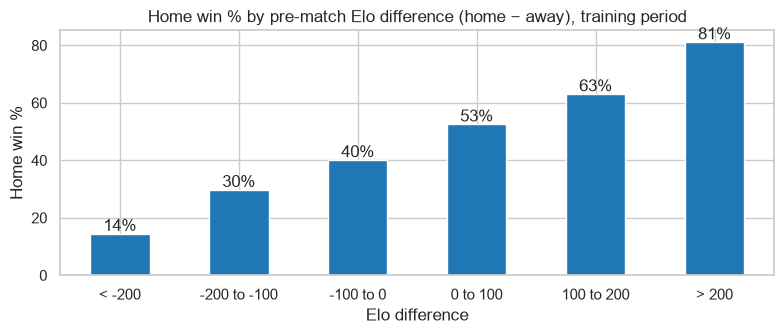

In [24]:
bands = pd.cut(train_data["elo_diff"], [-2000, -200, -100, 0, 100, 200, 2000],
               labels=["< -200", "-200 to -100", "-100 to 0", "0 to 100", "100 to 200", "> 200"])
home_win = (train_data["home_score"] > train_data["away_score"]).groupby(bands, observed=True).mean() * 100
ax = home_win.plot(kind="bar", rot=0, figsize=(8, 3.5), color="tab:blue")
ax.set(title="Home win % by pre-match Elo difference (home − away), training period",
       xlabel="Elo difference", ylabel="Home win %")
for i, v in enumerate(home_win):
    ax.text(i, v + 1, f"{v:.0f}%", ha="center")
plt.tight_layout(); plt.show()

### 4.2 How strongly is each feature related to the targets?

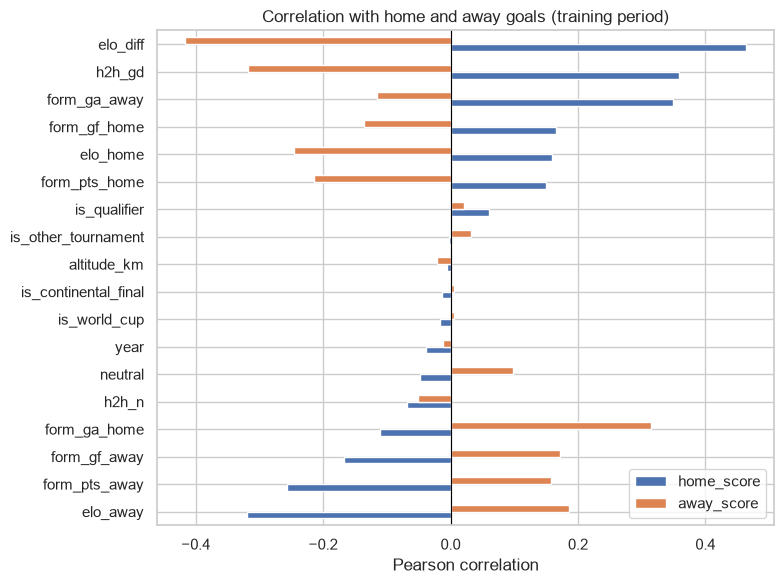

,home_score,away_score
elo_diff,0.464,-0.417
h2h_gd,0.359,-0.318
form_ga_away,0.348,-0.116
form_gf_home,0.166,-0.137
elo_home,0.160,-0.245
form_pts_home,0.149,-0.214
is_qualifier,0.060,0.021
is_other_tournament,-0.002,0.032
altitude_km,-0.005,-0.021
is_continental_final,-0.014,0.005


In [25]:
corr = pd.DataFrame({target: train_data[FEATURES + ["elo_diff"]].corrwith(train_data[target])
                     for target in TARGETS})
ax = corr.sort_values("home_score").plot(kind="barh", figsize=(8, 6))
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Correlation with home and away goals (training period)", xlabel="Pearson correlation")
plt.tight_layout(); plt.show()
corr.round(3).sort_values("home_score", ascending=False)

### 4.3 Altitude

In [26]:
at_home = train_data[train_data["neutral"] == 0]
high = at_home["altitude_km"] > 0
print(f"Training matches at a venue of 1,500 m or higher: {high.sum():,} "
      f"(test period: {(data.loc[data['period'] == 'test', 'altitude_km'] > 0).sum()})")
pd.DataFrame({
    "matches": [high.sum(), (~high).sum()],
    "home goals": [at_home.loc[high, "home_score"].mean(), at_home.loc[~high, "home_score"].mean()],
    "away goals": [at_home.loc[high, "away_score"].mean(), at_home.loc[~high, "away_score"].mean()],
    "home win %": [100 * (at_home.loc[high, "home_score"] > at_home.loc[high, "away_score"]).mean(),
                   100 * (at_home.loc[~high, "home_score"] > at_home.loc[~high, "away_score"]).mean()],
}, index=["venue ≥ 1,500 m", "lower venues"]).round(2)

Training matches at a venue of 1,500 m or higher: 675 (test period: 51)


,matches,home goals,away goals,home win %
"venue ≥ 1,500 m",675,1.60,0.85,53.33
lower venues,18028,1.67,1.01,50.69


### 4.4 Missing values in the features

In [27]:
missing = data.loc[data["period"].isin(["train", "test"]), FEATURES].isna()
print("Missing values per period:")
print(missing.groupby(data["period"], observed=True).sum().loc[:, lambda d: d.sum() > 0])
data.loc[missing.index[missing.any(axis=1)], ["date", "home_team", "away_team", "period", "n_prev_home", "n_prev_away"]]

Missing values per period:
        form_gf_home  form_ga_home  form_pts_home  form_gf_away  form_ga_away  \
period                                                                          
train              5             5              5             4             4   
test               0             0              0             0             0   

        form_pts_away  
period                 
train               4  
test                0  


,date,home_team,away_team,period,n_prev_home,n_prev_away
18745,1994-02-23,Turkey,Czech Republic,train,10,0
19833,1995-11-30,Albania,Bosnia and Herzegovina,train,10,0
20626,1996-11-13,Andorra,Estonia,train,0,10
21738,1998-03-22,United States Virgin Islands,British Virgin Islands,train,0,10
22394,1999-02-24,Bahamas,Turks and Caicos Islands,train,1,0
25923,2003-03-21,Sri Lanka,Timor-Leste,train,10,0
29686,2007-07-04,Gibraltar,Bermuda,train,0,10
34349,2012-07-10,South Sudan,Uganda,train,0,10
35823,2014-03-05,Kosovo,Haiti,train,0,10


### 4.5 Feature observations

- **The Elo ratings behave as they should.** The home team wins 14% of the time when it is rated more than 200 points lower, and 81% when it is rated more than 200 points higher, with a steady rise in between. At the end of the training period (Aug 2023) the top three are Argentina (2202), Brazil (2180) and France (2163) — the 2022 world champion and the two other strongest teams of that time. Among the CONMEBOL teams Bolivia is lowest (1677), and the chart shows known stories such as Venezuela's rise from about 1,300 around 2000 to about 1,800.
- **The strongest single signal is the rating difference** (r = 0.46 with home goals, −0.42 with away goals), followed by the head-to-head record (0.36 / −0.32) and how many goals the *opponent* has been conceding (0.35 / 0.32). `elo_diff` itself is not a model feature, because it is exactly `elo_home − elo_away` and would make the normal equation unsolvable; a linear model can rebuild it from the two ratings.
- **`neutral`, the tournament dummies, `year` and `altitude_km` are hardly correlated with the goals on their own.** That doesn't make them useless: home advantage, for example, works *together* with team strength. Whether they help will show in the models (sections 7–10).
- **Altitude:** 675 training matches were played at venues of 1,500 m or higher. There, away teams score 0.85 goals per match against 1.01 elsewhere, and the home team wins 53.3% against 50.7%. Only 4% of matches are at altitude, which is why the overall correlation is close to 0.
- **Missing values:** 9 training matches have no recent form, because they are the **first matches of new national teams** (e.g. Czech Republic 1994, Kosovo 2014, South Sudan 2012). The test period has none. They are filled with training medians in section 6. A related limitation: successor states such as the Czech Republic start at Elo 1500 instead of inheriting their predecessor's rating.

## 5. Define features and target

- **Targets (y):** `home_score` and `away_score` — two numbers per match. Both algorithms predict them together (our scratch model fits one coefficient column per target; the random forest supports several targets natively).
- **Features (X):** the 17 pre-match features from section 4. They are all numeric already, so no encoding is needed; scaling and filling the few missing form values happen in section 6, fitted on the training data only.

In [28]:
FEATURE_DESCRIPTIONS = {
    "elo_home": "Elo rating of the home team before the match",
    "elo_away": "Elo rating of the away team before the match",
    "form_gf_home": f"Home team: goals scored per match, last {FORM_WINDOW} matches",
    "form_ga_home": f"Home team: goals conceded per match, last {FORM_WINDOW} matches",
    "form_pts_home": f"Home team: points per match (3/1/0), last {FORM_WINDOW} matches",
    "form_gf_away": f"Away team: goals scored per match, last {FORM_WINDOW} matches",
    "form_ga_away": f"Away team: goals conceded per match, last {FORM_WINDOW} matches",
    "form_pts_away": f"Away team: points per match (3/1/0), last {FORM_WINDOW} matches",
    "h2h_gd": f"Mean goal difference (home view) in the last {H2H_WINDOW} meetings, 0 if none",
    "h2h_n": f"Number of earlier meetings counted (0-{H2H_WINDOW})",
    "neutral": "1 if played on neutral ground",
    "altitude_km": "Venue altitude in km for venues at 1,500 m or higher, else 0",
    "is_world_cup": "1 if a World Cup match",
    "is_continental_final": "1 if a continental championship match (Copa América, Euro, ...)",
    "is_qualifier": "1 if a qualifier or Nations League match",
    "is_other_tournament": "1 if another tournament (friendly = all four are 0)",
    "year": "Calendar year of the match",
}
assert list(FEATURE_DESCRIPTIONS) == FEATURES

X = data[FEATURES]
y = data[TARGETS]
print("X:", X.shape, "| y:", y.shape)
pd.Series(FEATURE_DESCRIPTIONS, name="meaning").to_frame()

X: (47380, 17) | y: (47380, 2)


,meaning
elo_home,Elo rating of the home team before the match
elo_away,Elo rating of the away team before the match
form_gf_home,"Home team: goals scored per match, last 10 mat..."
form_ga_home,"Home team: goals conceded per match, last 10 m..."
form_pts_home,"Home team: points per match (3/1/0), last 10 m..."
form_gf_away,"Away team: goals scored per match, last 10 mat..."
form_ga_away,"Away team: goals conceded per match, last 10 m..."
form_pts_away,"Away team: points per match (3/1/0), last 10 m..."
h2h_gd,Mean goal difference (home view) in the last 5...
h2h_n,Number of earlier meetings counted (0-5)


## 6. Split into training and test sets

The matches are a **time series**: a team's strength in 2024 is not something we could have known in 2010. A random 80/20 split would put matches from 2024 in the training set and matches from 2010 in the test set, so the model would partly learn from the future and its test score would be too optimistic. We therefore split **by date**:

| Set | Period | Used for |
|---|---|---|
| **Training** | 1 Jan 1994 → 31 Aug 2023 | fitting both models; tuning with time-series cross-validation |
| **Test — all** | 1 Sep 2023 → 9 Sep 2025 | final evaluation on all matches between FIFA teams in the 2026 qualifying period |
| **Test — CONMEBOL** | the 90 CONMEBOL World Cup qualifiers inside that window | the main evaluation for our topic |

**Missing values.** The 9 training matches without recent form (debut matches of new teams, section 4.4) are filled with the **training medians**. The same medians are used for the test set, so nothing is learned from it.

In [29]:
train_df = data[data["period"] == "train"].reset_index(drop=True)
test_df = data[data["period"] == "test"].reset_index(drop=True)

X_train, y_train = train_df[FEATURES], train_df[TARGETS]
X_test, y_test = test_df[FEATURES], test_df[TARGETS]
conmebol_test = test_df["is_conmebol_wcq"].to_numpy()

train_medians = X_train.median()
X_train = X_train.fillna(train_medians)
X_test = X_test.fillna(train_medians)            # training medians - nothing is learned from the test set

pd.DataFrame({
    "matches": [len(train_df), len(test_df), conmebol_test.sum()],
    "from": [train_df["date"].min().date(), test_df["date"].min().date(), test_df.loc[conmebol_test, "date"].min().date()],
    "to": [train_df["date"].max().date(), test_df["date"].max().date(), test_df.loc[conmebol_test, "date"].max().date()],
    "missing values": [int(X_train.isna().sum().sum()), int(X_test.isna().sum().sum()), int(X_test[conmebol_test].isna().sum().sum())],
}, index=["training", "test - all", "test - CONMEBOL qualifiers"])

,matches,from,to,missing values
training,25266,1994-01-02,2023-08-31,0
test - all,2269,2023-09-02,2025-09-09,0
test - CONMEBOL qualifiers,90,2023-09-07,2025-09-09,0


**Validation inside the training set.** For tuning and for choosing the final model (sections 7 and 8) we use `TimeSeriesSplit` with 5 folds: every fold trains on all matches up to a date and validates on the period right after it, so the model never trains on the future.

In [30]:
tscv = TimeSeriesSplit(n_splits=5)
folds = [{"fold": k + 1,
          "train until": train_df.loc[tr[-1], "date"].date(),
          "validate from": train_df.loc[va[0], "date"].date(),
          "validate until": train_df.loc[va[-1], "date"].date(),
          "train matches": len(tr), "validation matches": len(va)}
         for k, (tr, va) in enumerate(tscv.split(X_train))]
pd.DataFrame(folds).set_index("fold")

,train until,validate from,validate until,train matches,validation matches
fold,,,,,
1,1999-09-28,1999-09-28,2004-06-09,4211,4211
2,2004-06-09,2004-06-09,2009-02-11,8422,4211
3,2009-02-11,2009-02-11,2013-09-10,12633,4211
4,2013-09-10,2013-09-10,2018-10-11,16844,4211
5,2018-10-11,2018-10-11,2023-08-31,21055,4211


The metrics (MAE, MSE, RMSE and R² per target and averaged over home and away goals) and our own cross-validation loop. The loop is used for the linear model in 7.7 and the default forest in 8.2; it checks that the rows are in date order, because `TimeSeriesSplit` makes the folds from row positions.

In [31]:
def regression_metrics(y_true, y_pred):
    """MAE, MSE, RMSE and R² per target, plus their average over the targets ("both")."""
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    err = y_pred - y_true
    table = pd.DataFrame({
        "MAE": np.abs(err).mean(axis=0),
        "MSE": (err ** 2).mean(axis=0),
        "RMSE": np.sqrt((err ** 2).mean(axis=0)),
        "R²": 1 - (err ** 2).sum(axis=0) / ((y_true - y_true.mean(axis=0)) ** 2).sum(axis=0),
    }, index=[t.replace("_score", " goals") for t in TARGETS])
    table.loc["both (average)"] = table.mean()
    return table

def check_sorted_by_date(dates, n_rows):
    """Raise a ValueError unless there is one date per row and the dates never go backwards.

    Used before every TimeSeriesSplit (our own loop below and the random-forest grid search):
    the folds are made from row positions, so unsorted rows would mean training on the future.
    """
    dates = pd.Series(np.asarray(dates))
    if len(dates) != n_rows:
        raise ValueError("dates must have one value per row of X")
    if not dates.is_monotonic_increasing:
        raise ValueError("rows must be sorted by date for time-series cross-validation")

def time_series_cv(make_model, X, Y, n_splits=5, dates=None):
    """Fit a fresh model on each TimeSeriesSplit fold; return the validation RMSE (average of both targets)
    per fold. `make_model` is a function that returns a new, unfitted model.

    TimeSeriesSplit only looks at row positions: it trains on the first rows and validates on the
    following ones. The rows of X and Y MUST therefore be in date order, otherwise the folds would
    train on the future. Pass `dates` (one per row) to have this checked.
    """
    if dates is not None:
        check_sorted_by_date(dates, len(X))
    X, Y = np.asarray(X, dtype=float), np.asarray(Y, dtype=float)
    scores = []
    for train_idx, valid_idx in TimeSeriesSplit(n_splits=n_splits).split(X):
        model = make_model().fit(X[train_idx], Y[train_idx])
        err = model.predict(X[valid_idx]) - Y[valid_idx]
        scores.append(np.sqrt((err ** 2).mean(axis=0)).mean())
    return np.array(scores)

## 7. Algorithm 1 — Linear Regression from scratch

As the guidelines require, this model is **implemented by us with NumPy only** — no regression model from scikit-learn or another library. The complete class is defined in 7.2; the same class is unit-tested in our repository (`tests/test_linear_regression.py`).

### 7.1 How it works

**Model.** For a match with feature vector $x$ (17 features), the predicted home and away goals are a weighted sum of the features plus an intercept:

$$\hat{y}_\text{home} = \theta_{0,h} + \sum_j \theta_{j,h}\, x_j \qquad \hat{y}_\text{away} = \theta_{0,a} + \sum_j \theta_{j,a}\, x_j$$

In matrix form $\hat{Y} = X_b\,\theta$, where $X_b$ is the feature matrix with a column of 1s added for the intercept, and $\theta$ has **one column per target**. Fitting both columns at once gives exactly the same result as two separate regressions on the same features (checked in the tests).

**Cost.** The mean squared error, plus an optional L2 (ridge) penalty on the coefficients — never on the intercept:

$$J(\theta) = \frac{1}{m}\sum_{i=1}^{m}\big(\hat{y}_i - y_i\big)^2 + \lambda \sum_{j\geq 1} \theta_j^2$$

**Fitting, way 1 — the normal equation** (closed form). Setting the gradient of $J$ to zero gives

$$\big(X_b^\top X_b + m\lambda I^*\big)\,\theta = X_b^\top Y$$

where $I^*$ is the identity matrix with a 0 for the intercept. We solve this linear system with `np.linalg.solve` instead of computing a matrix inverse, which is faster and numerically more stable.

**Fitting, way 2 — batch gradient descent.** Start with $\theta = 0$ and repeatedly step downhill:

$$\theta \leftarrow \theta - \eta \Big[\tfrac{2}{m} X_b^\top (X_b\theta - Y) + 2\lambda\,\theta^*\Big]$$

with learning rate $\eta$ and $\theta^*$ = θ with the intercept row set to 0. It stops after `n_iters` steps or when the cost improves by less than `tol`. The cost is convex, so gradient descent cannot get stuck in a local minimum and must end at the same θ as the normal equation.

**Standardisation.** The features are on very different scales (Elo ≈ 1,500, dummies 0/1, altitude 0–4). Before fitting, every feature is standardised with the **training** mean and standard deviation (stored in `fit`, reused in `predict`). Gradient descent needs this — otherwise the cost surface is a long narrow valley and the steps barely move — and it makes the coefficients comparable with each other.

### 7.2 The code

In [32]:
class LinearRegressionScratch:
    """Multi-output linear regression fitted with the normal equation or batch gradient descent.

    Parameters
    ----------
    method : "normal" or "gradient"
    learning_rate : step size for gradient descent
    n_iters : maximum number of gradient-descent iterations
    l2 : strength of the L2 (ridge) penalty; 0 = ordinary least squares
    tol : gradient descent stops when the cost improves by less than this
    standardize : standardise the features with the training mean / std

    Attributes after fit
    --------------------
    theta_ : (n_features + 1, n_targets) - row 0 is the intercept
    intercept_, coef_ : the same split into intercept (n_targets,) and coefficients (n_features, n_targets)
    loss_history_ : cost after every gradient-descent iteration (empty for the normal equation)
    n_iter_ : number of iterations used
    """

    def __init__(self, method="normal", learning_rate=0.05, n_iters=5000, l2=0.0, tol=1e-10, standardize=True):
        if method not in ("normal", "gradient"):
            raise ValueError("method must be 'normal' or 'gradient'")
        self.method = method
        self.learning_rate = learning_rate
        self.n_iters = n_iters
        self.l2 = l2
        self.tol = tol
        self.standardize = standardize

    # ---------- helpers ----------
    @staticmethod
    def _as_2d(a, name):
        a = np.asarray(a, dtype=float)
        if a.ndim == 1:
            a = a.reshape(-1, 1)
        if not np.all(np.isfinite(a)):
            raise ValueError(f"{name} contains missing or infinite values - fill them before fitting")
        return a

    def _scale(self, X):
        return (X - self.mean_) / self.std_ if self.standardize else X

    @staticmethod
    def _add_bias(X):
        return np.hstack([np.ones((X.shape[0], 1)), X])

    def _cost(self, Xb, Y, theta):
        residuals = Xb @ theta - Y
        mse = np.mean(residuals ** 2)                       # averaged over rows and targets
        return mse + self.l2 * np.sum(theta[1:] ** 2) / Y.shape[1]

    # ---------- fit / predict ----------
    def fit(self, X, Y):
        X = self._as_2d(X, "X")
        Y = self._as_2d(Y, "Y")
        self._single_target = np.ndim(Y) == 2 and Y.shape[1] == 1
        m, n = X.shape

        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        self.std_ = np.where(std > 0, std, 1.0)            # a constant column stays as it is
        Xb = self._add_bias(self._scale(X))

        penalty = np.eye(n + 1)
        penalty[0, 0] = 0.0                                  # never penalise the intercept

        if self.method == "normal":
            A = Xb.T @ Xb + m * self.l2 * penalty
            self.theta_ = np.linalg.solve(A, Xb.T @ Y)       # solve A theta = X_b^T Y (no explicit inverse)
            self.loss_history_ = []
            self.n_iter_ = 0
        else:
            theta = np.zeros((n + 1, Y.shape[1]))
            history = [self._cost(Xb, Y, theta)]
            for i in range(1, self.n_iters + 1):
                gradient = (2 / m) * Xb.T @ (Xb @ theta - Y) + 2 * self.l2 * (penalty @ theta)
                theta = theta - self.learning_rate * gradient
                cost = self._cost(Xb, Y, theta)
                if not np.isfinite(cost) or cost > 1e6 * history[0]:
                    raise RuntimeError(f"gradient descent diverged at iteration {i} - lower the learning_rate")
                history.append(cost)
                if abs(history[-2] - cost) < self.tol:
                    break
            self.theta_ = theta
            self.loss_history_ = history
            self.n_iter_ = len(history) - 1

        self.intercept_ = self.theta_[0]
        self.coef_ = self.theta_[1:]
        return self

    def predict(self, X):
        if not hasattr(self, "theta_"):
            raise RuntimeError("call fit() before predict()")
        X = self._as_2d(X, "X")
        Y_hat = self._add_bias(self._scale(X)) @ self.theta_
        return Y_hat.ravel() if self._single_target else Y_hat

    def get_params(self):
        return {k: getattr(self, k) for k in ("method", "learning_rate", "n_iters", "l2", "tol", "standardize")}

    def __repr__(self):
        args = ", ".join(f"{k}={v!r}" for k, v in self.get_params().items())
        return f"LinearRegressionScratch({args})"

**What the unit tests check** (`tests/test_linear_regression.py` in our repository, run with `pytest`): the normal equation recovers a known θ exactly; the predictions equal NumPy's least-squares solution (`np.linalg.lstsq`, plain linear algebra); gradient descent converges to the normal-equation θ, with and without L2; the cost never increases during gradient descent; a too-large learning rate is detected; two targets at once equal two separate fits; L2 shrinks the coefficients but not the intercept; missing values are rejected.

### 7.3 Fitting on the training data — both ways

In [33]:
start = time.perf_counter()
lr_normal = LinearRegressionScratch(method="normal").fit(X_train, y_train)
t_normal = time.perf_counter() - start

start = time.perf_counter()
lr_gd = LinearRegressionScratch(method="gradient", learning_rate=0.1, n_iters=20_000, tol=1e-12).fit(X_train, y_train)
t_gd = time.perf_counter() - start

print(f"Normal equation : {t_normal:.3f} s")
print(f"Gradient descent: {t_gd:.1f} s, {lr_gd.n_iter_} iterations, final cost {lr_gd.loss_history_[-1]:.5f}")
print(f"Largest difference between the two θ: {np.abs(lr_gd.theta_ - lr_normal.theta_).max():.1e}")

Normal equation : 0.008 s
Gradient descent: 1.1 s, 414 iterations, final cost 1.62114
Largest difference between the two θ: 7.1e-06


### 7.4 Choosing the learning rate

How large can the learning rate be? For this cost, gradient descent is stable only if $\eta < 1/\lambda_\max$, where $\lambda_\max$ is the largest eigenvalue of $X_b^\top X_b / m$ (computed on the standardised training features).

Largest eigenvalue 3.698 -> stable for a learning rate below 0.270
Condition number 28 (small = gradient descent converges quickly)


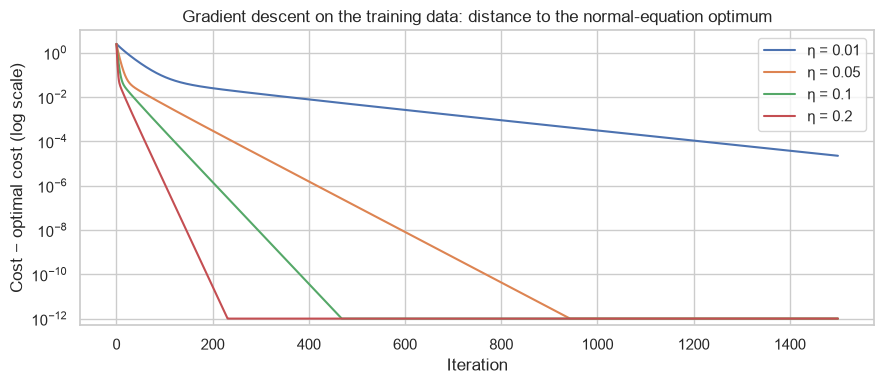

η = 0.3: gradient descent diverged at iteration 49 - lower the learning_rate


In [34]:
Xs = (X_train - X_train.mean()) / X_train.std(ddof=0)
Xb = np.column_stack([np.ones(len(Xs)), Xs])
eigenvalues = np.linalg.eigvalsh(Xb.T @ Xb / len(Xb))
print(f"Largest eigenvalue {eigenvalues.max():.3f} -> stable for a learning rate below {1 / eigenvalues.max():.3f}")
print(f"Condition number {eigenvalues.max() / eigenvalues.min():.0f} (small = gradient descent converges quickly)")

optimum = lr_normal._cost(Xb, y_train.to_numpy(float), lr_normal.theta_)
fig, ax = plt.subplots(figsize=(9, 4))
for eta in [0.01, 0.05, 0.1, 0.2]:
    gd = LinearRegressionScratch(method="gradient", learning_rate=eta, n_iters=1500, tol=0).fit(X_train, y_train)
    # below ~1e-12 the difference is only floating-point rounding, so the curve is cut there
    ax.plot(np.clip(np.array(gd.loss_history_) - optimum, 1e-12, None), label=f"η = {eta}")
ax.set(yscale="log", ylim=(5e-13, 10), xlabel="Iteration", ylabel="Cost − optimal cost (log scale)",
       title="Gradient descent on the training data: distance to the normal-equation optimum")
ax.legend()
plt.tight_layout(); plt.show()

try:
    LinearRegressionScratch(method="gradient", learning_rate=0.3, n_iters=2000).fit(X_train, y_train)
except RuntimeError as error:
    print("η = 0.3:", error)

### 7.5 The learned coefficients

Intercepts (= mean goals, because the features are standardised): [1.622 1.078]


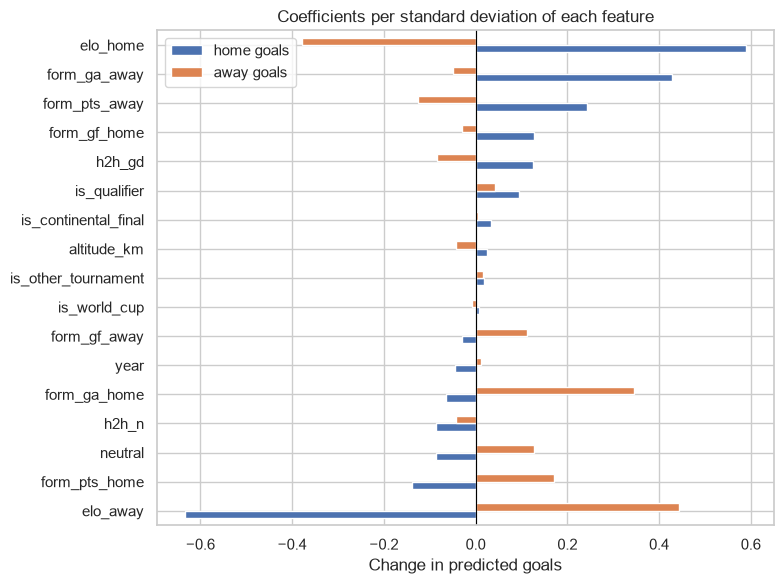

,home goals,away goals
elo_home,0.589,-0.379
form_ga_away,0.429,-0.049
form_pts_away,0.243,-0.125
form_gf_home,0.127,-0.030
h2h_gd,0.125,-0.084
is_qualifier,0.094,0.043
is_continental_final,0.033,0.005
altitude_km,0.024,-0.042
is_other_tournament,0.018,0.016
is_world_cup,0.008,-0.009


In [35]:
coefficients = pd.DataFrame(lr_normal.coef_, index=FEATURES, columns=["home goals", "away goals"])
print("Intercepts (= mean goals, because the features are standardised):", lr_normal.intercept_.round(3))

ax = coefficients.sort_values("home goals").plot(kind="barh", figsize=(8, 6))
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Coefficients per standard deviation of each feature", xlabel="Change in predicted goals")
plt.tight_layout(); plt.show()
coefficients.round(3).sort_values("home goals", ascending=False)

In [36]:
def fit_scores(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true, float), np.asarray(y_pred, float)
    return pd.DataFrame({
        "MAE": np.abs(y_true - y_pred).mean(axis=0),
        "RMSE": np.sqrt(((y_true - y_pred) ** 2).mean(axis=0)),
        "R²": 1 - ((y_true - y_pred) ** 2).sum(axis=0) / ((y_true - y_true.mean(axis=0)) ** 2).sum(axis=0),
    }, index=TARGETS)

print("Fit on the TRAINING data (the test set is evaluated in section 9):")
fit_scores(y_train, lr_normal.predict(X_train)).round(3)

Fit on the TRAINING data (the test set is evaluated in section 9):


,MAE,RMSE,R²
home_score,1.036,1.406,0.277
away_score,0.839,1.126,0.234


### 7.6 Observations

- **Both ways of fitting give the same model.** The largest difference between the gradient-descent θ and the normal-equation θ is about 7 · 10⁻⁶. The normal equation takes a few hundredths of a second; gradient descent needs 414 iterations (about a second) with η = 0.1. With only 17 features the normal equation is the practical choice; gradient descent is what would scale to many more features.
- **The learning rate behaves as the theory says.** The largest eigenvalue of $X_b^\top X_b/m$ is 3.70, so gradient descent is stable only for η < 0.27 — and η = 0.3 indeed diverges after 49 iterations. η = 0.2 converges fastest, η = 0.01 is still far from the optimum after 1,500 iterations. We use η = 0.1, which leaves a safety margin. The condition number is only 28 because the features are standardised; without standardisation gradient descent would hardly move.
- **What the model learned** (converted back to the original units):
  - **Team strength dominates.** A home team rated 100 Elo points higher scores about 0.25 more goals and concedes about 0.16 fewer; the same holds the other way round for the away team.
  - **The opponent's defence matters.** Every extra goal per match the away team has been conceding adds about 0.51 goals to the predicted home score (and the home team's conceding adds 0.44 to the away score).
  - **Home advantage:** on neutral ground the home team scores about 0.20 fewer goals and the away team 0.29 more — together about half a goal of goal difference.
  - **Altitude:** each kilometre adds about 0.06 home goals and removes about 0.10 away goals — in La Paz (3.64 km) about +0.21 and −0.37 compared with sea level. It is small overall, but it points in the direction section 3.7 suggested.
- **Not every coefficient can be read on its own.** `form_pts_home` gets a *negative* coefficient for home goals, although more points should mean more goals. It is strongly correlated with the home team's Elo (r = 0.68), goals scored (0.73) and goals conceded (−0.69), so the model splits their shared effect between them (**multicollinearity**). The predictions are fine; the individual coefficients of correlated features are not.
- **Fit on the training data:** R² = 0.28 for home goals and 0.23 for away goals, MAE 1.04 and 0.84 goals. That is modest but expected — goals are rare, noisy events. Whether the model beats simple baselines on unseen matches is the real test (section 9).

### 7.7 Tuning λ with time-series cross-validation

The only hyperparameter of our model that changes the result is the L2 strength λ (the learning rate only changes how fast gradient descent gets there). We compare λ = 0, 0.001, 0.01, 0.1, 1 and 10 with the 5 time-ordered folds from section 6: for every fold a **fresh model** is fitted on the earlier matches and scored on the following period (RMSE averaged over home and away goals). Our own loop (`time_series_cv`, section 6) is used, because our model is not a scikit-learn estimator; it checks that the rows are in date order, since the folds are made from row positions.

**Is the L2 penalty fair to all features?** Yes: the penalty depends on the scale of each coefficient, so `LinearRegressionScratch` standardises every feature with the mean and standard deviation of the data it is fitted on (in each fold: that fold's training part) before fitting, and it never penalises the intercept (row 0 of the penalty matrix is 0 — checked by `test_l2_shrinks_the_coefficients_but_not_the_intercept`).

In [37]:
L2_GRID = [0, 0.001, 0.01, 0.1, 1, 10]
FOLDS = [f"fold {k}" for k in range(1, 6)]
cv_rmse = pd.DataFrame({l2: time_series_cv(lambda: LinearRegressionScratch(l2=l2), X_train, y_train,
                                           dates=train_df["date"])
                                                for l2 in L2_GRID}, index=FOLDS).T
cv_rmse.index.name = "λ"
cv_rmse["mean"] = cv_rmse.mean(axis=1)
lowest_l2 = float(cv_rmse["mean"].idxmin())
print(f"Lowest mean validation RMSE: λ = {lowest_l2} ({cv_rmse.loc[lowest_l2, 'mean']:.4f}); "
      f"λ = 0: {cv_rmse.loc[0, 'mean']:.4f}")
cv_rmse.round(4)

Lowest mean validation RMSE: λ = 0.01 (1.2528); λ = 0: 1.2530


,fold 1,fold 2,fold 3,fold 4,fold 5,mean
λ,,,,,,
0.000,1.3724,1.2456,1.2159,1.2034,1.2273,1.2530
0.001,1.3725,1.2456,1.2159,1.2034,1.2273,1.2529
0.010,1.3726,1.2453,1.2154,1.2034,1.2272,1.2528
0.100,1.3783,1.2479,1.2166,1.2075,1.2320,1.2565
1.000,1.4209,1.2829,1.2418,1.2406,1.2734,1.2919
10.000,1.5331,1.3892,1.3317,1.3319,1.3827,1.3937


The mean RMSE differs by only 0.0002 between λ = 0 and λ = 0.01, while the folds differ from each other by about 0.07 — so the means alone can't tell these values apart. Because every λ is scored on **the same five folds**, the fair comparison is **fold by fold** (paired): how much better or worse is each λ than λ = 0 *in the same fold*?

In [38]:
paired = cv_rmse[FOLDS].sub(cv_rmse.loc[0, FOLDS], axis=1)
paired["worse than λ = 0 in"] = (paired[FOLDS] > 1e-9).sum(axis=1).astype(str) + " of 5 folds"
paired["mean difference"] = paired[FOLDS].mean(axis=1)

# the classic one-standard-error rule, for comparison: largest λ within one SE of the lowest mean
fold_std = cv_rmse.loc[lowest_l2, FOLDS].std(ddof=1)
threshold = cv_rmse.loc[lowest_l2, "mean"] + fold_std / np.sqrt(len(FOLDS))
one_se_choice = max(l2 for l2 in L2_GRID if cv_rmse.loc[l2, "mean"] <= threshold)
print(f"Spread between folds (std): {fold_std:.4f} -> classic one-SE rule would choose λ = {one_se_choice}")
paired.round(5)

Spread between folds (std): 0.0687 -> classic one-SE rule would choose λ = 0.1


,fold 1,fold 2,fold 3,fold 4,fold 5,worse than λ = 0 in,mean difference
λ,,,,,,,
0.000,0.00000,0.00000,0.00000,0.00000,0.00000,0 of 5 folds,0.00000
0.001,0.00000,-0.00004,-0.00006,-0.00002,-0.00003,1 of 5 folds,-0.00003
0.010,0.00016,-0.00030,-0.00047,-0.00007,-0.00011,1 of 5 folds,-0.00016
0.100,0.00584,0.00230,0.00065,0.00409,0.00465,5 of 5 folds,0.00351
1.000,0.04846,0.03729,0.02592,0.03711,0.04606,5 of 5 folds,0.03897
10.000,0.16063,0.14358,0.11582,0.12847,0.15536,5 of 5 folds,0.14077


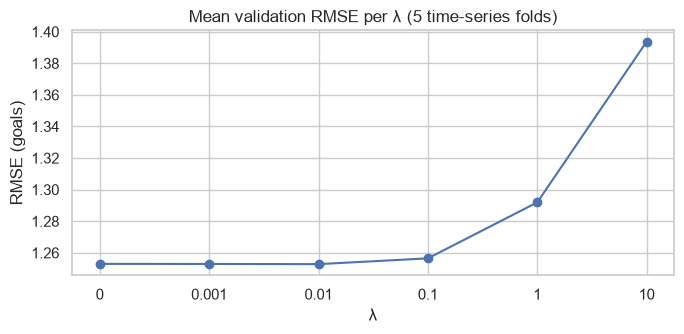

Final model: LinearRegressionScratch(method='normal', learning_rate=0.05, n_iters=5000, l2=0.01, tol=1e-10, standardize=True)


In [39]:
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot([str(l2) for l2 in L2_GRID], cv_rmse["mean"], marker="o")
ax.set(title="Mean validation RMSE per λ (5 time-series folds)", xlabel="λ", ylabel="RMSE (goals)")
plt.tight_layout(); plt.show()

best_l2 = 0.01        # chosen in the text below: the largest λ that is as good as no penalty
lr_final = LinearRegressionScratch(method="normal", l2=best_l2).fit(X_train, y_train)
print("Final model:", lr_final)

**Result — the L2 penalty is irrelevant here.**

- **λ = 0, 0.001 and 0.01 are equivalent.** Fold by fold they differ from λ = 0 by at most 0.0005 goals, in both directions. Calling one of them "the best" would be reading noise.
- **From λ = 0.1 the model gets worse in every one of the five folds**, and the more so the larger λ is.
- **Our choice: λ = 0.01**, the largest value that is still as good as no penalty (the idea behind the one-standard-error rule: among equally good models, prefer the more regularised one). In practice this is the same model as plain least squares.
- The **classic one-standard-error rule** would choose λ = 0.1. It measures the uncertainty with the spread *between* folds, but that spread mostly reflects that some periods are harder to predict for *every* λ (the first fold, 1999–2004, is the hardest in every row). The paired comparison removes that shared part — and shows that λ = 0.1 is worse in all five folds, so we don't follow the classic rule here.

Why doesn't regularisation help? It fights overfitting, and a linear model with 17 features and 25,000 training matches hardly overfits (training RMSE 1.27 against 1.25 in the validation folds) — the same thing happened with Ridge in Lab 1.

In [40]:
# Guard: every number quoted in the text above is recomputed here, so "Run All" fails if text and results drift apart.
def check_quoted(quoted):
    """quoted: {description: (value typed in the text, computed value, allowed difference)}"""
    table = pd.DataFrame([{"quoted in the text": text, "typed": typed, "computed": float(value),
                           "ok": abs(float(value) - typed) <= tol}
                          for text, (typed, value, tol) in quoted.items()]).set_index("quoted in the text")
    assert table["ok"].all(), f"The text and the results disagree:\n{table[~table['ok']]}"
    return table.round(4)

small = [0.001, 0.01]
check_quoted({
    "mean RMSE, λ = 0.01": (1.2528, cv_rmse.loc[0.01, "mean"], 5e-5),
    "mean RMSE, λ = 0": (1.2530, cv_rmse.loc[0, "mean"], 5e-5),
    "difference of the means, λ = 0 vs 0.01": (0.0002, cv_rmse.loc[0, "mean"] - cv_rmse.loc[0.01, "mean"], 5e-5),
    "spread between folds (std)": (0.07, fold_std, 0.005),
    "largest |fold difference| for λ ≤ 0.01": (0.0005, paired.loc[small, FOLDS].abs().max().max(), 5e-5),
    "λ = 0.1 worse in n of 5 folds": (5, (paired.loc[0.1, FOLDS] > 0).sum(), 0),
    "λ = 1 worse in n of 5 folds": (5, (paired.loc[1, FOLDS] > 0).sum(), 0),
    "classic one-SE rule chooses λ": (0.1, one_se_choice, 0),
    "training RMSE, λ = 0.01": (1.27, regression_metrics(y_train, lr_final.predict(X_train)).loc["both (average)", "RMSE"], 0.005),
    "validation RMSE, λ = 0.01": (1.25, cv_rmse.loc[0.01, "mean"], 0.005),
})

,typed,computed,ok
quoted in the text,,,
"mean RMSE, λ = 0.01",1.2528,1.2528,True
"mean RMSE, λ = 0",1.2530,1.2530,True
"difference of the means, λ = 0 vs 0.01",0.0002,0.0002,True
spread between folds (std),0.0700,0.0687,True
largest |fold difference| for λ ≤ 0.01,0.0005,0.0005,True
λ = 0.1 worse in n of 5 folds,5.0000,5.0000,True
λ = 1 worse in n of 5 folds,5.0000,5.0000,True
classic one-SE rule chooses λ,0.1000,0.1000,True
"training RMSE, λ = 0.01",1.2700,1.2657,True


## 8. Algorithm 2 — Random Forest Regressor

For the second algorithm a library may be used, so we use scikit-learn's `RandomForestRegressor`. The forest and its tuning helpers are defined below (tested in `tests/test_random_forest.py` in our repository).

### 8.1 How it works

- **One decision tree** splits the training matches again and again on one feature and a threshold (e.g. *"`elo_away` < 1650?"*), each time choosing the split that lowers the squared error the most. A leaf predicts the **mean home and away goals** of the training matches that end up in it. A deep tree can fit the training data almost perfectly — including its noise (high variance).
- **A forest** grows many trees, each on a **bootstrap sample** (as many matches as the training set, drawn with replacement — about 63% of the matches, some several times), and each split only tries a random share of the features (`max_features`). The trees make different mistakes, so their **average** varies much less than a single tree.
- **Two targets at once.** Every leaf stores the mean home *and* away goals, and a split is chosen to lower the squared error summed over both targets: one forest, two predictions — like the two θ columns in section 7.
- **No scaling, no straight lines.** A split only compares a feature with a threshold, so the scale of a feature doesn't matter, and the forest can learn non-linear effects and interactions by itself (e.g. an altitude effect that only appears above some height).
- **Predictions stay inside the range of the training data.** A leaf averages real scores, so the forest can never predict negative goals (the linear model can). The flip side: it can't extrapolate beyond what it has seen.
- **Out-of-bag (OOB) predictions.** Every match is missing from about 37% of the bootstrap samples. Predicting it with only those trees gives an almost free estimate of how the forest does on matches it was not trained on. We use it in sections 8.5 and 9.1.

| Hyperparameter | What it controls | Values tried (`PARAM_GRID`) |
|---|---|---|
| `n_estimators` | Number of trees. More trees make the average smoother — they can't cause overfitting, they only cost time | 200, 500 |
| `max_depth` | How many levels of splits a tree may have (`None` = until the leaves are pure or too small) | None, 10, 20 |
| `min_samples_leaf` | Fewest training matches allowed in a leaf — larger leaves average more matches, so predictions are smoother | 1, 5, 20 |
| `max_features` | Share of the 17 features tried at each split — fewer makes the trees more different from each other | 1.0 (all 17), 0.5 (8), `"sqrt"` (4) |

In [41]:
# Saved result of the full grid search (see 8.3)
GRID_CACHE = RESULTS_DIR / "rf_grid_cv_results.csv"

# The grid: 2 x 3 x 3 x 3 = 54 combinations, x 5 folds = 270 fits.
PARAM_GRID = {
    "n_estimators": [200, 500],          # more trees = smoother average (never overfits, only slower)
    "max_depth": [None, 10, 20],         # how deep a tree may grow (None = until the leaves are pure / too small)
    "min_samples_leaf": [1, 5, 20],      # fewest training matches allowed in a leaf - larger = smoother predictions
    "max_features": [1.0, 0.5, "sqrt"],  # share of the features tried at each split (1.0 = all, "sqrt" = 4 of 17)
}
SCORING = "neg_root_mean_squared_error"  # scikit-learn maximises scores, so the RMSE comes back negated

def make_forest(n_jobs=-1, **params):
    """A RandomForestRegressor with our fixed random_state; any parameter can be overridden."""
    return RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=n_jobs, **params)

def grid_search_forest(X, Y, dates, param_grid=PARAM_GRID, n_splits=5, n_jobs=-1):
    """Try every combination in `param_grid` on the TimeSeriesSplit folds of the training data.

    The rows must be in date order (checked with `dates`), because TimeSeriesSplit builds the folds
    from row positions. The parallel work is spread over the grid (one fit per CPU core); the forests
    themselves run on one core each, so the cores are not over-subscribed.

    refit=False: the search only chooses the parameters. The final model is fitted explicitly
    afterwards, on the whole training window, so it is visible in the notebook what is fitted on what.
    Returns the fitted GridSearchCV object; use `cv_results_table` to read it.
    """
    check_sorted_by_date(dates, len(X))
    search = GridSearchCV(make_forest(n_jobs=1), param_grid, scoring=SCORING,
                          cv=TimeSeriesSplit(n_splits=n_splits), n_jobs=n_jobs,
                          refit=False, return_train_score=True)
    return search.fit(np.asarray(X, dtype=float), np.asarray(Y, dtype=float))

def cv_results_table(search):
    """One row per parameter combination, best first: the validation RMSE of every fold, its mean and
    standard deviation, the mean training RMSE (to see overfitting) and the mean fit time per fold."""
    res = search.cv_results_
    n_splits = search.n_splits_
    params = list(res["params"])
    # dtype=object keeps the values exactly as given: otherwise pandas turns [None, 10, 20] into
    # [NaN, 10.0, 20.0], and a float max_depth is rejected by RandomForestRegressor.
    table = pd.DataFrame({k: pd.Series([p[k] for p in params], dtype=object) for k in params[0]})
    for k in range(n_splits):
        table[f"fold {k + 1}"] = -res[f"split{k}_test_score"]
    folds = [f"fold {k + 1}" for k in range(n_splits)]
    table["mean"] = table[folds].mean(axis=1)
    table["std"] = table[folds].std(axis=1, ddof=1)
    table["train RMSE"] = -res["mean_train_score"]
    table["fit time (s)"] = res["mean_fit_time"]
    return table.sort_values("mean", kind="stable").reset_index(drop=True)

FINGERPRINT_DECIMALS = 9

def data_fingerprint(X, Y):
    """SHA-256 of the training features and targets in row order, rounded to 9 decimals.

    The rounding makes the fingerprint the same on every computer: another NumPy version or CPU can change
    the last binary digit of a computed feature (about 1e-13 here), which must not invalidate the cache,
    while any real change in the data, the features or their order still changes the fingerprint."""
    h = hashlib.sha256()
    for a in (X, Y):
        rounded = np.round(np.asarray(a, dtype=float), FINGERPRINT_DECIMALS) + 0.0   # + 0.0 turns -0.0 into 0.0
        h.update(np.ascontiguousarray(rounded).tobytes())
    return h.hexdigest()

def save_cv_results(table, X, Y, path=GRID_CACHE, n_jobs=None, minutes=None):
    """Write the cv_results_table to `path` (CSV) and its metadata to the same name with .json."""
    path.parent.mkdir(parents=True, exist_ok=True)
    table.to_csv(path, index=False)
    meta = {"fingerprint": data_fingerprint(X, Y), "rows": int(len(X)), "features": int(np.shape(X)[1]),
            "combinations": int(len(table)), "created": date.today().isoformat(),
            "grid_n_jobs": n_jobs, "minutes": None if minutes is None else round(minutes, 1)}
    path.with_suffix(".json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    return meta

def _restore(text):
    """Turn a CSV cell back into the original parameter value.
    '' or 'None' -> None, '500' -> 500 (int), '0.5' / '1.0' -> float, 'sqrt' -> 'sqrt'.
    The int/float difference matters: max_features=1.0 means "all features", max_features=1 means one."""
    if text in ("", "None"):
        return None
    try:
        return int(text)
    except ValueError:
        pass
    try:
        return float(text)
    except ValueError:
        return text

def load_cv_results(X, Y, path=GRID_CACHE, param_grid=PARAM_GRID):
    """Read a cached cv_results_table. Raises FileNotFoundError if the CSV or its .json metadata is missing,
    and ValueError if it was made from other training data or with another grid - then the search has to be
    run again."""
    for required in (path, path.with_suffix(".json")):
        if not required.exists():
            raise FileNotFoundError(f"cache file missing: {required.name}")
    meta = json.loads(path.with_suffix(".json").read_text(encoding="utf-8"))
    if meta["fingerprint"] != data_fingerprint(X, Y):
        raise ValueError("the cached grid search was made with different training data - run it again")
    table = pd.read_csv(path, dtype=str, keep_default_na=False)
    for p in param_grid:
        table[p] = pd.Series([_restore(v) for v in table[p]], dtype=object)
    for col in table.columns.difference(list(param_grid)):
        table[col] = table[col].astype(float)
    cached = {tuple(map(str, row)) for row in table[list(param_grid)].itertuples(index=False)}
    expected = {tuple(map(str, combo)) for combo in itertools.product(*param_grid.values())}
    if cached != expected:
        raise ValueError("the cached grid search used a different parameter grid - run it again")
    return table, meta

### 8.2 Before tuning: the default forest

scikit-learn's defaults are 100 trees, no depth limit, leaves of a single match and all features at every split. We score it on the **same five time-series folds** as λ in section 7.7, with the same RMSE (our `time_series_cv`), so the numbers can be compared directly with the linear model.

In [42]:
rf_default_cv = time_series_cv(lambda: make_forest(), X_train, y_train, dates=train_df["date"])
rf_default = make_forest(oob_score=True).fit(X_train, y_train)

def rmse_both(y_true, y_pred):
    # RMSE per target, averaged over home and away goals - the number used for all tuning
    return regression_metrics(y_true, y_pred).loc["both (average)", "RMSE"]

before = pd.DataFrame({
    f"Linear Regression (scratch, λ = {best_l2})": [rmse_both(y_train, lr_final.predict(X_train)),
                                                    *cv_rmse.loc[best_l2, FOLDS + ["mean"]]],
    "Random Forest (default)": [rmse_both(y_train, rf_default.predict(X_train)), *rf_default_cv, rf_default_cv.mean()],
}, index=["training RMSE"] + [f"validation RMSE, {f}" for f in FOLDS] + ["validation RMSE, mean"]).T
before.round(4)

,training RMSE,"validation RMSE, fold 1","validation RMSE, fold 2","validation RMSE, fold 3","validation RMSE, fold 4","validation RMSE, fold 5","validation RMSE, mean"
"Linear Regression (scratch, λ = 0.01)",1.2657,1.3726,1.2453,1.2154,1.2034,1.2272,1.2528
Random Forest (default),0.4748,1.3890,1.2699,1.2414,1.2392,1.2363,1.2752


**Observations — the default forest overfits strongly**

- **Strong overfitting on the training set:** The default forest reaches a training RMSE of **0.4748** goals (and training $R^2 \approx 0.895$), compared to an average validation RMSE of **1.2752** across the 5 folds. With no limits on depth or minimum samples per leaf, each tree splits down to single matches (averaging over **11,682** leaves per tree). The forest largely memorises the training scores, including their noise.
- **Worse than the simple linear model on unseen folds:** On the validation folds, the default forest (1.2752) performs worse than our scratch linear regression (1.2528) in **5 of 5 folds** (e.g. fold 1: 1.3890 vs 1.3726).
- **Takeaway:** Hyperparameter tuning is not optional here. Without constraints on tree complexity and feature sampling, the forest's high capacity leads to overfitting.

### 8.3 Grid search with time-series cross-validation

`grid_search_forest` runs scikit-learn's `GridSearchCV` over all 2 × 3 × 3 × 3 = **54 combinations** of `PARAM_GRID`, each on the **5 time-ordered folds** from section 6 — 270 forests. That takes 20–30 minutes on a 16 GB laptop (the largest forests need about 0.9 GB each, so only 3 are fitted in parallel). Because the notebook is run many times, the result table of one full run is **saved in `results/rf_grid_cv_results.csv`** together with a fingerprint of the training data. If that file is found and matches the training data, the features and the grid, it is loaded; **otherwise the full search runs here** and saves its result. The fingerprint is computed on values rounded to 9 decimals, so tiny floating-point differences between computers (another NumPy version or CPU) don't invalidate it. Set `RUN_GRID_SEARCH = True` to always run the full search again (it overwrites the file). It first checks that the rows are in date order (the folds are made from row positions), and it never sees the test period. The scorer is scikit-learn's RMSE averaged over the two targets; a unit test (`tests/test_random_forest.py`) checks that it gives exactly the same numbers per fold as our `time_series_cv`, so the forest and the linear model are compared on equal terms.

In [43]:
RUN_GRID_SEARCH = False   # True: always rerun the full search (20-30 min) and overwrite the saved result
GRID_N_JOBS = 3           # the largest forests need about 0.9 GB each, so 3 parallel fits fit in a 16 GB laptop
PARAMS = list(PARAM_GRID)

grid = None
if not RUN_GRID_SEARCH:
    try:
        grid, grid_meta = load_cv_results(X_train, y_train)
        print(f"Loaded the grid search of {grid_meta['created']} from {GRID_CACHE.name} "
              f"(full run: {grid_meta['minutes']} min with {grid_meta['grid_n_jobs']} parallel fits; "
              f"training-data fingerprint matches)")
    except (FileNotFoundError, ValueError, KeyError) as error:
        print(f"No usable saved grid search ({error}) - running the full search now (20-30 minutes).")
if grid is None:
    start = time.perf_counter()
    search = grid_search_forest(X_train, y_train, dates=train_df["date"], n_jobs=GRID_N_JOBS)
    grid = cv_results_table(search)
    grid_meta = save_cv_results(grid, X_train, y_train, n_jobs=GRID_N_JOBS,
                                minutes=(time.perf_counter() - start) / 60)
    print(f"Ran the full grid search in {grid_meta['minutes']} minutes and saved it to {GRID_CACHE}")
print(f"{len(grid)} combinations x 5 folds. The 12 best (lowest mean validation RMSE first):")
grid.head(12).round(4)

Loaded the grid search of 2026-10-21 from rf_grid_cv_results.csv (full run: 20.1 min with 3 parallel fits; training-data fingerprint matches)
54 combinations x 5 folds. The 12 best (lowest mean validation RMSE first):


,max_depth,max_features,min_samples_leaf,n_estimators,fold 1,fold 2,fold 3,fold 4,fold 5,mean,std,train RMSE,fit time (s)
0,10,0.5,5,500,1.3647,1.2340,1.2048,1.1987,1.2128,1.2430,0.0693,1.1568,10.9441
1,10,0.5,5,200,1.3653,1.2343,1.2061,1.1982,1.2134,1.2435,0.0694,1.1580,4.3851
2,None,0.5,5,500,1.3655,1.2379,1.2058,1.1991,1.2109,1.2438,0.0696,0.9710,16.8116
3,20,0.5,5,500,1.3660,1.2377,1.2052,1.1995,1.2111,1.2439,0.0698,0.9792,15.3770
4,20,0.5,5,200,1.3672,1.2382,1.2059,1.1993,1.2118,1.2445,0.0702,0.9798,6.1246
5,None,0.5,5,200,1.3668,1.2385,1.2067,1.1998,1.2119,1.2447,0.0698,0.9715,7.1830
6,10,1.0,5,500,1.3683,1.2378,1.2069,1.1998,1.2117,1.2449,0.0705,1.1345,21.7314
7,None,sqrt,5,500,1.3722,1.2384,1.2056,1.1983,1.2124,1.2454,0.0725,1.0227,8.9674
8,10,1.0,5,200,1.3687,1.2374,1.2081,1.2009,1.2118,1.2454,0.0703,1.1356,8.8437
9,20,sqrt,5,500,1.3724,1.2378,1.2053,1.1990,1.2128,1.2455,0.0725,1.0300,8.7930


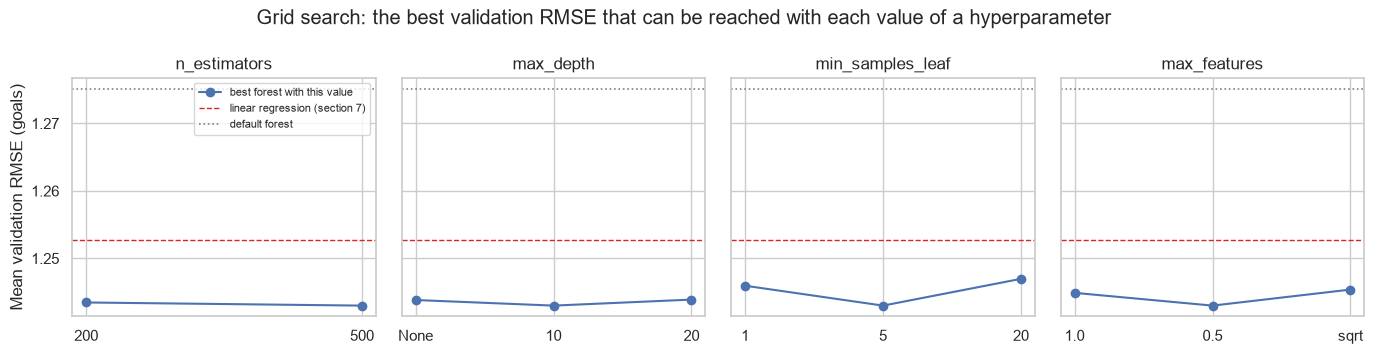

In [44]:
fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), sharey=True)
for ax, param in zip(axes, PARAMS):
    values = [str(v) for v in PARAM_GRID[param]]
    best_per_value = grid.groupby(grid[param].map(str))["mean"].min().reindex(values)
    ax.plot(values, best_per_value.values, marker="o", label="best forest with this value")
    ax.axhline(cv_rmse.loc[best_l2, "mean"], color="tab:red", ls="--", lw=1, label="linear regression (section 7)")
    ax.axhline(rf_default_cv.mean(), color="grey", ls=":", lw=1.2, label="default forest")
    ax.set(title=param)
axes[0].set_ylabel("Mean validation RMSE (goals)")
axes[0].legend(fontsize=8, loc="upper right")
fig.suptitle("Grid search: the best validation RMSE that can be reached with each value of a hyperparameter")
plt.tight_layout(); plt.show()

### 8.4 Is the best combination really better? Fold by fold

As in section 7.7, the differences between the folds (some periods are simply harder to predict) are much larger than the differences between models, so we compare **fold by fold**: the best combination against the default forest and against our linear regression, on the same five folds.

In [45]:
best_params = {p: grid.loc[0, p] for p in PARAMS}
best_folds = grid.loc[0, FOLDS].to_numpy(float)
paired_rf = pd.DataFrame({
    "best combination − default forest": best_folds - rf_default_cv,
    "best combination − linear regression": best_folds - cv_rmse.loc[best_l2, FOLDS].to_numpy(float),
}, index=FOLDS).T
paired_rf["better in"] = (paired_rf[FOLDS] < 0).sum(axis=1).astype(str) + " of 5 folds"
paired_rf["mean difference"] = paired_rf[FOLDS].mean(axis=1)

near_best = grid[grid["mean"] <= grid.loc[0, "mean"] + 0.001]
print("Best combination:", best_params)
print(f"Combinations within 0.001 goals of the best: {len(near_best)}")
print(near_best[PARAMS].map(str).value_counts().to_string())
paired_rf.round(4)

Best combination: {'n_estimators': 500, 'max_depth': 10, 'min_samples_leaf': 5, 'max_features': 0.5}
Combinations within 0.001 goals of the best: 4
n_estimators  max_depth  min_samples_leaf  max_features
500           10         5                 0.5             1
200           10         5                 0.5             1
500           None       5                 0.5             1
              20         5                 0.5             1


,fold 1,fold 2,fold 3,fold 4,fold 5,better in,mean difference
best combination − default forest,-0.0244,-0.0358,-0.0366,-0.0405,-0.0236,5 of 5 folds,-0.0322
best combination − linear regression,-0.0079,-0.0113,-0.0106,-0.0047,-0.0145,5 of 5 folds,-0.0098


### 8.5 The final forest: before and after tuning

The best combination is fitted on the **whole training window**, with `oob_score=True` so that the out-of-bag predictions are kept. Before and after tuning are compared on the **training period only** — training, out-of-bag and validation RMSE. The test set is not used until the two final models are evaluated in section 9.

In [46]:
rf_final = make_forest(oob_score=True, **best_params).fit(X_train, y_train)
print("Final model:", rf_final)

before_after = pd.DataFrame({
    name: {"leaves per tree": np.mean([tree.get_n_leaves() for tree in model.estimators_]),
           "training RMSE": rmse_both(y_train, model.predict(X_train)),
           "out-of-bag RMSE": rmse_both(y_train, model.oob_prediction_),
           "validation RMSE (5 folds)": cv}
    for name, model, cv in [("before tuning (default)", rf_default, rf_default_cv.mean()),
                            ("after tuning", rf_final, grid.loc[0, "mean"])]
}).T
before_after.round(4)

Final model: RandomForestRegressor(max_depth=10, max_features=0.5, min_samples_leaf=5,
                      n_estimators=500, n_jobs=-1, oob_score=True,
                      random_state=42)


,leaves per tree,training RMSE,out-of-bag RMSE,validation RMSE (5 folds)
before tuning (default),11682.110,0.4748,1.2802,1.2752
after tuning,399.228,1.1533,1.2512,1.2430


### 8.6 Observations — Random Forest after tuning

- **Much less overfitting:**
  - The average number of leaves per tree shrinks from **11,682** down to **399** (a 97% reduction in tree complexity).
  - Training RMSE increases from **0.4748** to **1.1533**, reflecting realistic, smoothed predictions rather than memorization.
  - Out-of-bag (OOB) RMSE drops from **1.2802** to **1.2512**, confirming that generalization on out-of-sample training matches improved.
- **Consistent improvement across all folds:**
  - The tuned forest achieves a mean validation RMSE of **1.2430** goals, improving over the default forest (1.2752) by **0.0322** goals.
  - In the paired fold-by-fold comparison, the tuned forest is better than the default forest in **5 of 5 folds**, and better than linear regression (1.2528) in **5 of 5 folds** (by ~0.0098 goals on average).
- **Which hyperparameters mattered?** The best validation RMSE that can be reached with each value (chart in 8.3):
  - `min_samples_leaf` matters most: **1.2430** with 5 matches per leaf, against **1.2460** with 1 and **1.2470** with 20. Leaves of a single match fit the noise; leaves of 20 matches are too coarse.
  - `max_features` comes next: **1.2430** with 0.5 (8 of 17 features per split), **1.2449** with all 17 and **1.2454** with `"sqrt"` (4). Trying fewer features makes the trees more different from each other, but with only 4 the splits get too weak.
  - `max_depth` hardly matters once the leaves have at least 5 matches: **1.2430** (10), **1.2438** (None), **1.2439** (20) — a difference of at most **0.0009** goals.
  - `n_estimators`: **1.2430** with 500 trees against **1.2435** with 200 — more trees average out a little more noise, but the gain is tiny.
  - All **4** combinations within 0.001 goals of the best share `min_samples_leaf = 5` and `max_features = 0.5`; they differ only in depth and number of trees. So the choice of those two settings is robust, the rest is close to noise.
- **No negative goal predictions:** a leaf averages real scores, so the forest can never predict a negative number of goals — unlike the linear model, whose straight line has no lower bound.

In [47]:
# Guard: every number quoted in 8.2-8.6 is recomputed here ("Run All" fails if text and results drift apart).
rf_def_leaves = np.mean([tree.get_n_leaves() for tree in rf_default.estimators_])
rf_fin_leaves = np.mean([tree.get_n_leaves() for tree in rf_final.estimators_])
rf_def_tr_rmse = rmse_both(y_train, rf_default.predict(X_train))
rf_fin_tr_rmse = rmse_both(y_train, rf_final.predict(X_train))
rf_def_oob_rmse = rmse_both(y_train, rf_default.oob_prediction_)
rf_fin_oob_rmse = rmse_both(y_train, rf_final.oob_prediction_)
lr_val_mean = cv_rmse.loc[best_l2, "mean"]

default_train_r2 = regression_metrics(y_train, rf_default.predict(X_train))["R²"].iloc[:2].mean()
per_value = {p: grid.groupby(grid[p].map(str))["mean"].min() for p in PARAMS}
near_best_n = int((grid["mean"] <= grid.loc[0, "mean"] + 0.001).sum())
near_best_shared = grid[grid["mean"] <= grid.loc[0, "mean"] + 0.001][["min_samples_leaf", "max_features"]].map(str).drop_duplicates()

check_quoted({
    "default forest: training R² (mean of both targets)": (0.895, default_train_r2, 0.005),
    "fold 1: default forest": (1.3890, rf_default_cv[0], 0.0005),
    "fold 1: linear regression": (1.3726, cv_rmse.loc[best_l2, "fold 1"], 0.0005),
    "default forest worse than linear regression in n of 5 folds": (5, (rf_default_cv > cv_rmse.loc[best_l2, FOLDS].to_numpy(float)).sum(), 0),
    "tuned forest vs linear regression: mean fold difference": (-0.0098, paired_rf.loc["best combination − linear regression", "mean difference"], 0.0005),
    "best RMSE, min_samples_leaf = 5": (1.2430, per_value["min_samples_leaf"]["5"], 0.00005),
    "best RMSE, min_samples_leaf = 1": (1.2460, per_value["min_samples_leaf"]["1"], 0.00005),
    "best RMSE, min_samples_leaf = 20": (1.2470, per_value["min_samples_leaf"]["20"], 0.00005),
    "best RMSE, max_features = 0.5": (1.2430, per_value["max_features"]["0.5"], 0.00005),
    "best RMSE, max_features = 1.0": (1.2449, per_value["max_features"]["1.0"], 0.00005),
    "best RMSE, max_features = sqrt": (1.2454, per_value["max_features"]["sqrt"], 0.00005),
    "best RMSE, max_depth = 10": (1.2430, per_value["max_depth"]["10"], 0.00005),
    "best RMSE, max_depth = None": (1.2438, per_value["max_depth"]["None"], 0.00005),
    "best RMSE, max_depth = 20": (1.2439, per_value["max_depth"]["20"], 0.00005),
    "largest depth effect": (0.0009, per_value["max_depth"].max() - per_value["max_depth"].min(), 0.00005),
    "best RMSE, 500 trees": (1.2430, per_value["n_estimators"]["500"], 0.00005),
    "best RMSE, 200 trees": (1.2435, per_value["n_estimators"]["200"], 0.00005),
    "combinations within 0.001 of the best": (4, near_best_n, 0),
    "near-best combinations share one leaf size and one max_features": (1, len(near_best_shared), 0),
    "default forest: training RMSE": (0.4748, rf_def_tr_rmse, 0.005),
    "default forest: validation RMSE mean": (1.2752, rf_default_cv.mean(), 0.005),
    "default forest: leaves per tree": (11682, rf_def_leaves, 150),
    "default forest: OOB RMSE": (1.2802, rf_def_oob_rmse, 0.005),
    "tuned forest: validation RMSE mean": (1.2430, grid.loc[0, "mean"], 0.005),
    "tuned forest: training RMSE": (1.1533, rf_fin_tr_rmse, 0.005),
    "tuned forest: OOB RMSE": (1.2512, rf_fin_oob_rmse, 0.005),
    "tuned forest: leaves per tree": (399, rf_fin_leaves, 15),
    "tuned vs default: better in n of 5 folds": (5, (paired_rf.loc["best combination − default forest", FOLDS] < 0).sum(), 0),
    "tuned vs linear regression: better in n of 5 folds": (5, (paired_rf.loc["best combination − linear regression", FOLDS] < 0).sum(), 0),
    "validation gain over default forest": (0.0322, rf_default_cv.mean() - grid.loc[0, "mean"], 0.005),
})

,typed,computed,ok
quoted in the text,,,
default forest: training R² (mean of both targets),0.8950,0.8954,True
fold 1: default forest,1.3890,1.3890,True
fold 1: linear regression,1.3726,1.3726,True
default forest worse than linear regression in n of 5 folds,5.0000,5.0000,True
tuned forest vs linear regression: mean fold difference,-0.0098,-0.0098,True
"best RMSE, min_samples_leaf = 5",1.2430,1.2430,True
"best RMSE, min_samples_leaf = 1",1.2460,1.2460,True
"best RMSE, min_samples_leaf = 20",1.2470,1.2470,True
"best RMSE, max_features = 0.5",1.2430,1.2430,True


### 8.7 Choosing the final model with cross-validation

Both algorithms are now tuned. Which one is our **final model**? Following the rule *choose with cross-validation, then evaluate on the test set once*, we decide on the **same five time-series folds** — still without looking at the test set. We look at all validation matches, and separately at the **CONMEBOL qualifiers inside the validation folds**, because they are our topic.

In [48]:
# Both tuned models, refitted on every fold (training data only), scored on all validation matches
# and on the CONMEBOL qualifiers inside each validation period
X_train_arr, y_train_arr = X_train.to_numpy(float), y_train.to_numpy(float)
wcq_in_train = (train_df["is_conmebol_wcq"] & (train_df["date"] >= "1996-01-01")).to_numpy()
selection_rows = []
for k, (tr, va) in enumerate(tscv.split(X_train_arr), start=1):
    lr_fold = LinearRegressionScratch(l2=best_l2).fit(X_train_arr[tr], y_train_arr[tr])
    rf_fold = make_forest(**best_params).fit(X_train_arr[tr], y_train_arr[tr])
    con = va[wcq_in_train[va]]
    selection_rows.append({
        "fold": f"fold {k}", "validation matches": len(va), "CONMEBOL qualifiers": len(con),
        "LR, all": rmse_both(y_train_arr[va], lr_fold.predict(X_train_arr[va])),
        "RF, all": rmse_both(y_train_arr[va], rf_fold.predict(X_train_arr[va])),
        "LR, CONMEBOL": rmse_both(y_train_arr[con], lr_fold.predict(X_train_arr[con])),
        "RF, CONMEBOL": rmse_both(y_train_arr[con], rf_fold.predict(X_train_arr[con])),
    })
selection = pd.DataFrame(selection_rows).set_index("fold")

# same folds and settings as 7.7 and 8.3, so the "all" columns must repeat those numbers
assert np.allclose(selection["LR, all"], cv_rmse.loc[best_l2, FOLDS].to_numpy(float), atol=1e-6)
assert np.allclose(selection["RF, all"], grid.loc[0, FOLDS].to_numpy(float), atol=1e-6)

rf_better_all = int((selection["RF, all"] < selection["LR, all"]).sum())
rf_better_con = int((selection["RF, CONMEBOL"] < selection["LR, CONMEBOL"]).sum())
final_name = ("Random Forest (tuned)" if selection["RF, all"].mean() < selection["LR, all"].mean()
              else "Linear Regression (scratch)")
print(f"Mean validation RMSE - all matches: LR {selection['LR, all'].mean():.4f}, RF {selection['RF, all'].mean():.4f} "
      f"(RF lower in {rf_better_all} of 5 folds)")
print(f"Mean validation RMSE - CONMEBOL qualifiers: LR {selection['LR, CONMEBOL'].mean():.4f}, "
      f"RF {selection['RF, CONMEBOL'].mean():.4f} (RF lower in {rf_better_con} of 5 folds)")
print("Final model (lowest mean validation RMSE):", final_name)
selection.round(4)

Mean validation RMSE - all matches: LR 1.2528, RF 1.2430 (RF lower in 5 of 5 folds)
Mean validation RMSE - CONMEBOL qualifiers: LR 1.1680, RF 1.1637 (RF lower in 3 of 5 folds)
Final model (lowest mean validation RMSE): Random Forest (tuned)


,validation matches,CONMEBOL qualifiers,"LR, all","RF, all","LR, CONMEBOL","RF, CONMEBOL"
fold,,,,,,
fold 1,4211,125,1.3726,1.3647,1.2173,1.2050
fold 2,4211,105,1.2453,1.2340,1.2365,1.2376
fold 3,4211,102,1.2154,1.2048,1.1593,1.1524
fold 4,4211,100,1.2034,1.1987,1.1238,1.1042
fold 5,4211,89,1.2272,1.2128,1.1030,1.1196


**Selected: the tuned Random Forest.** It has the lower validation RMSE in **all five folds** (1.243 against 1.253 on average). On the CONMEBOL qualifiers inside the folds it is also slightly better on average (1.164 against 1.168), although there the linear model is ahead in 2 of the 5 folds. The difference is small — about 0.01 goals — so the two algorithms are close, but the rule is clear and the choice is made before the test set is used.

Section 9 evaluates **both** tuned models on the test set, because the project compares the two algorithms; the two baselines are included as reference points. Nothing is tuned or chosen after that.

In [49]:
# Guard: every number quoted in 8.7 is recomputed here.
check_quoted({
    "RF lower validation RMSE in n of 5 folds (all)": (5, rf_better_all, 0),
    "mean validation RMSE, RF (all)": (1.243, selection["RF, all"].mean(), 0.0005),
    "mean validation RMSE, LR (all)": (1.253, selection["LR, all"].mean(), 0.0005),
    "mean validation RMSE, RF (CONMEBOL)": (1.164, selection["RF, CONMEBOL"].mean(), 0.0005),
    "mean validation RMSE, LR (CONMEBOL)": (1.168, selection["LR, CONMEBOL"].mean(), 0.0005),
    "LR ahead on CONMEBOL in n of 5 folds": (2, 5 - rf_better_con, 0),
    "difference of the means (all)": (0.01, selection["LR, all"].mean() - selection["RF, all"].mean(), 0.0015),
    "selected model is the forest": (1, int(final_name == "Random Forest (tuned)"), 0),
})

,typed,computed,ok
quoted in the text,,,
RF lower validation RMSE in n of 5 folds (all),5.000,5.0000,True
"mean validation RMSE, RF (all)",1.243,1.2430,True
"mean validation RMSE, LR (all)",1.253,1.2528,True
"mean validation RMSE, RF (CONMEBOL)",1.164,1.1637,True
"mean validation RMSE, LR (CONMEBOL)",1.168,1.1680,True
LR ahead on CONMEBOL in n of 5 folds,2.000,2.0000,True
difference of the means (all),0.010,0.0098,True
selected model is the forest,1.000,1.0000,True


## 9. Evaluate the models

All models are fitted on the **training period only** and evaluated on the two test sets from section 6. We compare them with two baselines that use no features at all:

| Baseline | Prediction |
|---|---|
| **Mean** | The average home and away goals of the training period (1.62 – 1.08) for every match |
| **Venue** | The training averages separately for home venues (1.67 – 1.00) and neutral venues (1.49 – 1.29) |

A model is only useful if it beats these. Metrics (`regression_metrics`, section 6): **MAE**, **MSE**, **RMSE** and **R²** per target and averaged over home and away goals. Note that R² on a test set compares the model with the mean *of that test set* — a number no model can know in advance — so on the small CONMEBOL set it can be negative even for a reasonable model; the comparison with the baselines is the fairer test.

In [50]:
# Baselines and win/draw/loss helpers
def outcomes(home, away, draw_band=0.0):
    """'H' (home win) / 'D' (draw) / 'A' (away win) from goals.

    A match is a draw when |home - away| < max(draw_band, 1e-9) - a strict inequality.
    The 1e-9 floor matters only for draw_band = 0 (used for real scores): "< 0" would never be
    true, so without the floor even 1 - 1 would not count as a draw. A difference exactly equal
    to a positive draw_band is NOT a draw."""
    diff = np.asarray(home, dtype=float) - np.asarray(away, dtype=float)
    result = np.where(diff > 0, "H", "A").astype(object)
    result[np.abs(diff) < max(draw_band, 1e-9)] = "D"
    return result

def choose_draw_band(y_true, y_pred, bands=np.arange(0, 1.01, 0.05)):
    """Draw band that maximises win/draw/loss accuracy on the given (training) predictions.

    A regression model almost never predicts exactly equal goals, so without a band it would
    never predict a draw. The band is chosen on the TRAINING data only.
    """
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    actual = outcomes(y_true[:, 0], y_true[:, 1])
    acc = [(outcomes(y_pred[:, 0], y_pred[:, 1], b) == actual).mean() for b in bands]
    return float(bands[int(np.argmax(acc))])

def outcome_scores(y_true, y_pred, draw_band):
    """Win/draw/loss accuracy and exact-score hit rate (predictions rounded, negatives set to 0)."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    actual = outcomes(y_true[:, 0], y_true[:, 1])
    predicted = outcomes(y_pred[:, 0], y_pred[:, 1], draw_band)
    rounded = np.clip(np.rint(y_pred), 0, None)
    return {
        "W/D/L accuracy": (predicted == actual).mean(),
        "exact score": (rounded == y_true).all(axis=1).mean(),
        "predicted draws": (predicted == "D").mean(),
        "negative predictions": int((y_pred < 0).sum()),
    }

class MeanBaseline:
    """Always predicts the training mean of home goals and of away goals."""

    def fit(self, X, Y):
        self.means_ = np.asarray(Y, dtype=float).mean(axis=0)
        return self

    def predict(self, X):
        return np.tile(self.means_, (len(X), 1))

class VenueBaseline:
    """Predicts the training mean home / away goals separately for home and neutral venues.

    X is a DataFrame with a `neutral` column (0/1), or - for plain arrays, e.g. inside
    `time_series_cv` - pass `neutral_index`, the position of that column. If one venue group has
    no training rows, it falls back to the overall training mean instead of returning NaN.
    """

    def __init__(self, neutral_column="neutral", neutral_index=None):
        self.neutral_column = neutral_column
        self.neutral_index = neutral_index

    def _is_neutral(self, X):
        if hasattr(X, "columns"):
            return np.asarray(X[self.neutral_column]) == 1
        if self.neutral_index is None:
            raise TypeError("VenueBaseline needs a DataFrame with a 'neutral' column, "
                            "or neutral_index=<column position> for plain arrays")
        return np.asarray(X)[:, self.neutral_index] == 1

    def fit(self, X, Y):
        Y = np.asarray(Y, dtype=float)
        neutral = self._is_neutral(X)
        overall = Y.mean(axis=0)
        self.means_ = {flag: Y[neutral == flag].mean(axis=0) if (neutral == flag).any() else overall
                       for flag in (False, True)}
        return self

    def predict(self, X):
        neutral = self._is_neutral(X)
        return np.where(neutral[:, None], self.means_[True], self.means_[False])

In [51]:
models = {
    "Mean baseline": MeanBaseline().fit(X_train, y_train),
    "Venue baseline": VenueBaseline().fit(X_train, y_train),
    "Linear Regression (scratch)": lr_final,
    "Random Forest (tuned)": rf_final,
}

test_sets = {"all test matches": np.ones(len(test_df), dtype=bool), "CONMEBOL qualifiers": conmebol_test}

rows = []
for name, model in models.items():
    for set_name, mask in test_sets.items():
        table = regression_metrics(y_test[mask], model.predict(X_test[mask]))
        for target, values in table.iterrows():
            rows.append({"test set": set_name, "target": target, "model": name, **values})
results = pd.DataFrame(rows).set_index(["test set", "target", "model"])

print("Average over home and away goals:")
results.xs("both (average)", level="target").round(3)

Average over home and away goals:


,,MAE,MSE,RMSE,R²
test set,model,,,,
all test matches,Mean baseline,1.079,2.079,1.432,-0.000
CONMEBOL qualifiers,Mean baseline,0.996,1.486,1.208,-0.142
all test matches,Venue baseline,1.074,2.063,1.427,0.007
CONMEBOL qualifiers,Venue baseline,0.974,1.463,1.196,-0.110
all test matches,Linear Regression (scratch),0.934,1.520,1.227,0.262
CONMEBOL qualifiers,Linear Regression (scratch),0.907,1.244,1.109,0.022
all test matches,Random Forest (tuned),0.936,1.517,1.225,0.264
CONMEBOL qualifiers,Random Forest (tuned),0.942,1.305,1.139,-0.046


In [52]:
print("Per target:")
results.drop(index="both (average)", level="target").round(3)

Per target:


MAE    MSE  \
test set            target     model                                       
all test matches    home goals Mean baseline                1.235  2.565   
                    away goals Mean baseline                0.923  1.593   
CONMEBOL qualifiers home goals Mean baseline                1.158  1.881   
                    away goals Mean baseline                0.835  1.091   
all test matches    home goals Venue baseline               1.226  2.541   
                    away goals Venue baseline               0.922  1.586   
CONMEBOL qualifiers home goals Venue baseline               1.167  1.901   
                    away goals Venue baseline               0.781  1.025   
all test matches    home goals Linear Regression (scratch)  1.019  1.818   
                    away goals Linear Regression (scratch)  0.848  1.223   
CONMEBOL qualifiers home goals Linear Regression (scratch)  1.018  1.505   
                    away goals Linear Regression (scratch)  0.796  0.983   
all test matches    home goals Random Forest (tuned)        1.029  1.823   
                    away goals Random Forest (tuned)        0.843  1.211   
CONMEBOL qualifiers home goals Random Forest (tuned)        1.027  1.516   
                    away goals Random Forest (tuned)        0.856  1.095   

                                                             RMSE     R²  
test set            target     model                                      
all test matches    home goals Mean baseline                1.602 -0.000  
                    away goals Mean baseline                1.262 -0.001  
CONMEBOL qualifiers home goals Mean baseline                1.372 -0.019  
                    away goals Mean baseline                1.045 -0.265  
all test matches    home goals Venue baseline               1.594  0.010  
                    away goals Venue baseline               1.259  0.004  
CONMEBOL qualifiers home goals Venue baseline               1.379 -0.030  
                    away goals Venue baseline               1.013 -0.189  
all test matches    home goals Linear Regression (scratch)  1.348  0.291  
                    away goals Linear Regression (scratch)  1.106  0.232  
CONMEBOL qualifiers home goals Linear Regression (scratch)  1.227  0.185  
                    away goals Linear Regression (scratch)  0.992 -0.141  
all test matches    home goals Random Forest (tuned)        1.350  0.289  
                    away goals Random Forest (tuned)        1.100  0.239  
CONMEBOL qualifiers home goals Random Forest (tuned)        1.231  0.179  
                    away goals Random Forest (tuned)        1.047 -0.270

### 9.1 Win / draw / loss and exact scores

The models predict goals, but the result of a match is what people care about. A predicted home win is `predicted home goals − predicted away goals > band`, a draw when the difference is smaller than the band. A regression model almost never predicts exactly equal goals, so the **draw band** is chosen per model to maximise the win/draw/loss accuracy **on the training data**. For the random forest the band is chosen on its **out-of-bag** predictions (section 8.1) instead: its predictions for its own training matches are too close to the real scores (training RMSE far below the validation RMSE, section 8.5), so in principle they could suggest a band that suits the training matches better than new ones. In practice it makes no difference: the out-of-bag and the in-sample predictions both give a band of 0 — like for every other model (checked in section 10). The out-of-bag predictions are not time-ordered, but they only use training matches, and the band is one number chosen from a fixed grid. For the exact score the predictions are rounded (and negative values set to 0).

In [53]:
train_predictions = {name: model.predict(X_train) for name, model in models.items()}
train_predictions["Random Forest (tuned)"] = rf_final.oob_prediction_     # see the text above
draw_bands = {name: choose_draw_band(y_train, pred) for name, pred in train_predictions.items()}
outcome_rows = []
for name, model in models.items():
    for set_name, mask in test_sets.items():
        scores = outcome_scores(y_test[mask], model.predict(X_test[mask]), draw_bands[name])
        outcome_rows.append({"test set": set_name, "model": name, "draw band": draw_bands[name], **scores})
outcome_table = pd.DataFrame(outcome_rows).set_index(["test set", "model"])

actual = test_df.loc[conmebol_test, "home_score"] - test_df.loc[conmebol_test, "away_score"]
print(f"Actual results of the 90 CONMEBOL qualifiers: home win {(actual > 0).mean():.1%}, "
      f"draw {(actual == 0).mean():.1%}, away win {(actual < 0).mean():.1%}")
outcome_table.round(3)

Actual results of the 90 CONMEBOL qualifiers: home win 54.4%, draw 30.0%, away win 15.6%


,,draw band,W/D/L accuracy,exact score,predicted draws,negative predictions
test set,model,,,,,
all test matches,Mean baseline,0.0,0.470,0.068,0.0,0
CONMEBOL qualifiers,Mean baseline,0.0,0.544,0.078,0.0,0
all test matches,Venue baseline,0.0,0.470,0.087,0.0,0
CONMEBOL qualifiers,Venue baseline,0.0,0.544,0.078,0.0,0
all test matches,Linear Regression (scratch),0.0,0.599,0.113,0.0,117
CONMEBOL qualifiers,Linear Regression (scratch),0.0,0.500,0.056,0.0,0
all test matches,Random Forest (tuned),0.0,0.595,0.106,0.0,0
CONMEBOL qualifiers,Random Forest (tuned),0.0,0.522,0.044,0.0,0


### 9.2 The 2026 CONMEBOL qualifiers, match by match

In [54]:
def prediction_table(model, mask):
    p = model.predict(X_test[mask])
    t = test_df.loc[mask, ["date", "home_team", "away_team", "city", "home_score", "away_score"]].copy()
    t["predicted"] = [f"{h:.1f} – {a:.1f}" for h, a in p]
    t["actual"] = t["home_score"].astype(str) + " – " + t["away_score"].astype(str)
    t["abs error"] = np.abs(p - t[["home_score", "away_score"]].to_numpy()).sum(axis=1)
    return t.drop(columns=["home_score", "away_score"])

conmebol_pred = prediction_table(lr_final, conmebol_test)
print("Linear Regression (scratch) - first round of the cycle:")
conmebol_pred.head(10)

Linear Regression (scratch) - first round of the cycle:


,date,home_team,away_team,city,predicted,actual,abs error
12,2023-09-07,Colombia,Venezuela,Barranquilla,2.0 – 0.6,1 – 0,1.598236
13,2023-09-07,Paraguay,Peru,Ciudad del Este,1.0 – 1.2,0 – 0,2.213831
14,2023-09-07,Argentina,Ecuador,Buenos Aires,2.2 – 0.5,1 – 0,1.714409
45,2023-09-08,Uruguay,Chile,Montevideo,1.8 – 0.6,3 – 1,1.558970
46,2023-09-08,Brazil,Bolivia,Belém,2.9 – 0.2,5 – 1,2.880569
122,2023-09-12,Bolivia,Argentina,La Paz,0.3 – 1.9,0 – 3,1.402433
123,2023-09-12,Ecuador,Uruguay,Quito,1.3 – 0.8,2 – 1,0.872020
124,2023-09-12,Venezuela,Paraguay,Maturín,1.2 – 1.0,1 – 0,1.266409
125,2023-09-12,Peru,Brazil,Lima,0.7 – 1.6,0 – 1,1.335745
126,2023-09-12,Chile,Colombia,Santiago,1.0 – 1.3,0 – 0,2.274143


In [55]:
print("Largest errors (home + away goals) in the CONMEBOL test set:")
conmebol_pred.sort_values("abs error", ascending=False).head(8)

Largest errors (home + away goals) in the CONMEBOL test set:


,date,home_team,away_team,city,predicted,actual,abs error
2239,2025-09-09,Venezuela,Colombia,Maturín,0.7 – 1.7,3 – 6,6.595414
1166,2024-09-05,Bolivia,Venezuela,El Alto,0.6 – 1.5,4 – 0,4.889572
1641,2024-11-19,Chile,Venezuela,Santiago,1.2 – 1.1,4 – 2,3.706130
340,2023-11-16,Argentina,Uruguay,Buenos Aires,2.1 – 0.7,0 – 2,3.415395
1475,2024-10-15,Argentina,Bolivia,Buenos Aires,2.9 – 0.1,6 – 0,3.285223
278,2023-10-17,Venezuela,Chile,Maturín,1.1 – 1.2,3 – 0,3.121126
1546,2024-11-15,Uruguay,Colombia,Montevideo,1.1 – 1.0,3 – 2,2.941074
46,2023-09-08,Brazil,Bolivia,Belém,2.9 – 0.2,5 – 1,2.880569


In [56]:
print("Bolivia's home matches (La Paz 3,640 m, El Alto 4,090 m):")
conmebol_pred[conmebol_pred["home_team"] == "Bolivia"]

Bolivia's home matches (La Paz 3,640 m, El Alto 4,090 m):


,date,home_team,away_team,city,predicted,actual,abs error
122,2023-09-12,Bolivia,Argentina,La Paz,0.3 – 1.9,0 – 3,1.402433
168,2023-10-12,Bolivia,Ecuador,La Paz,0.8 – 1.3,1 – 2,0.857461
337,2023-11-16,Bolivia,Peru,La Paz,0.9 – 1.0,2 – 0,2.052956
1166,2024-09-05,Bolivia,Venezuela,El Alto,0.6 – 1.5,4 – 0,4.889572
1337,2024-10-10,Bolivia,Colombia,El Alto,0.5 – 1.8,1 – 0,2.257877
1638,2024-11-19,Bolivia,Paraguay,El Alto,1.4 – 1.3,2 – 2,1.317427
1871,2025-03-25,Bolivia,Uruguay,El Alto,0.4 – 1.8,0 – 0,2.191667
2049,2025-06-10,Bolivia,Chile,El Alto,1.4 – 1.2,2 – 0,1.784663
2238,2025-09-09,Bolivia,Brazil,El Alto,0.4 – 1.7,1 – 0,2.283358


### 9.3 Checking our explanations on the training period

The results on the CONMEBOL test set (9.2) suggest two explanations: a **stronger home advantage in South American qualifiers** than in international football in general, and an **altitude effect** the model under-estimates. Before writing them down as findings, we check whether the model makes the same kind of error on the **CONMEBOL qualifiers of the training period (1996–2022)**. This uses only training data, so it doesn't touch the test set and doesn't change the model.

In [57]:
train_pred = lr_final.predict(X_train)
y_train_arr = y_train.to_numpy(dtype=float)

def mean_pred_vs_actual(mask):
    return pd.Series({"matches": int(mask.sum()),
                      "home goals predicted": train_pred[mask, 0].mean(), "home goals actual": y_train_arr[mask, 0].mean(),
                      "away goals predicted": train_pred[mask, 1].mean(), "away goals actual": y_train_arr[mask, 1].mean()})

wcq_train = (train_df["is_conmebol_wcq"] & (train_df["date"] >= "1996-01-01")).to_numpy()
home_venue = (train_df["neutral"] == 0).to_numpy()
home_team = train_df["home_team"].to_numpy()
explanation_checks = pd.DataFrame({
    "CONMEBOL qualifiers 1996-2022": mean_pred_vs_actual(wcq_train),
    "all other matches at a home venue": mean_pred_vs_actual(~wcq_train & home_venue),
    "  Bolivia at home (La Paz)": mean_pred_vs_actual(wcq_train & (home_team == "Bolivia")),
    "  Ecuador at home (Quito)": mean_pred_vs_actual(wcq_train & (home_team == "Ecuador")),
    "  the other 8 teams at home": mean_pred_vs_actual(wcq_train & ~np.isin(home_team, ["Bolivia", "Ecuador"])),
}).T
explanation_checks.round(2)

,matches,home goals predicted,home goals actual,away goals predicted,away goals actual
CONMEBOL qualifiers 1996-2022,593.0,1.59,1.67,1.02,0.95
all other matches at a home venue,18110.0,1.67,1.67,1.00,1.01
Bolivia at home (La Paz),61.0,1.20,1.66,1.21,1.18
Ecuador at home (Quito),61.0,1.62,1.72,0.89,0.72
the other 8 teams at home,471.0,1.63,1.66,1.01,0.95


### 9.4 Observations — Algorithm 1 against the baselines

**All 2,269 test matches.** Our linear regression is clearly better than both baselines on every metric: average MAE 0.93 against 1.07 goals, RMSE 1.23 against 1.43, and R² 0.29 for home goals and 0.23 for away goals — almost exactly the training values (0.28 and 0.23), so the model **generalises to 2023–2025 without overfitting**. Outside the CONMEBOL qualifiers its average predictions are well calibrated (home 1.58 predicted vs 1.63 actual, away 1.10 vs 1.13). It gets the result right in 59.9% of the matches against 47.0% for the baselines (which always predict a home win), and the exact score in 11.3% against 6.8–8.7%.

**The 90 CONMEBOL qualifiers.** The model still beats the baselines on the goal errors — MAE 0.91 against 0.97 and RMSE 1.11 against 1.20 — but the gain is smaller, and on the match result it is *worse*: 50.0% correct against 54.4% for "always a home win". What we see, and what we think explains it:

1. **Visiting teams scored far less than the model expected:** 0.98 away goals predicted per match, 0.60 actual (home goals are close: 1.36 vs 1.43). This is also why R² for away goals is negative here (−0.14). *Likely explanation:* the home advantage in South American qualifiers is stronger than the international average the model learned (altitude, long journeys, climate, hostile stadiums). **The training period supports the direction but not the size:** in the 1996–2022 qualifiers the model also over-predicts away goals, but only by 0.07 (1.02 vs 0.95), while it is spot on for all other matches at a home venue (1.00 vs 1.01). So part of the gap is probably a real CONMEBOL effect, and most of it seems specific to the 2026 cycle, which had unusually few away wins (15.6%). With 90 matches we can't separate the two.
2. **It never predicts a draw.** On the training data no draw band improves the accuracy (the best band is 0), because draws are the hardest result to tell apart from narrow wins. In this cycle 27 of the 90 matches were draws, and all of them count as misses. Of the other matches it gets 35 of 49 home wins and 10 of 14 away wins right; 14 home wins were predicted as away wins.
3. **Bolivia in El Alto.** The largest errors are Bolivia's home matches at El Alto (4,090 m), where Bolivia beat Venezuela 4–0, Colombia 1–0, Chile 2–0 and Brazil 1–0 while the model predicted defeats. *Likely explanation:* the altitude effect is stronger than the model can represent. **The training period supports this:** even in La Paz (3,640 m) the model under-predicts Bolivia's home goals (1.20 vs 1.66), and in Quito it under-predicts Ecuador's home goals (1.62 vs 1.72) and over-predicts their visitors' (0.89 vs 0.72), while for the other eight teams it is close (1.63 vs 1.66 and 1.01 vs 0.95). The learned altitude effect is small and linear, El Alto never appears in the training data, and Bolivia has the lowest Elo rating in CONMEBOL. It remains a hypothesis: all 6 matches in El Alto are in the test period.

**Other limitations.** 117 of the 2,269 test predictions are negative (strong teams playing away against very weak ones): a linear model has no lower bound at 0. They are only clipped for the exact-score check.

> **We do not fix these problems by changing the features now.** That would mean tuning the model on the test set, and the result would no longer be an honest estimate. They are discussed as limitations and future work instead (a competition-specific home advantage, a non-linear altitude effect, a model for count data such as Poisson regression, and a way to predict draws).

In [58]:
# Guard: every number quoted in 9.4 is recomputed here ("Run All" fails if text and results drift apart).
LR = "Linear Regression (scratch)"
BASELINES = ["Mean baseline", "Venue baseline"]
res_all = results.xs("all test matches", level="test set")
res_con = results.xs("CONMEBOL qualifiers", level="test set")
both = "both (average)"
best_baseline = lambda res, col: res.loc[[(both, b) for b in BASELINES], col].min()
train_r2 = regression_metrics(y_train, train_pred)["R²"]
other = ~conmebol_test
pred_test = lr_final.predict(X_test)
y_test_arr = y_test.to_numpy(dtype=float)
oc_all = outcome_table.xs("all test matches", level="test set")
oc_con = outcome_table.xs("CONMEBOL qualifiers", level="test set")

pred_out = outcomes(pred_test[conmebol_test, 0], pred_test[conmebol_test, 1], draw_bands[LR])
true_out = outcomes(y_test_arr[conmebol_test, 0], y_test_arr[conmebol_test, 1])
c = explanation_checks

check_quoted({
    "all: MAE, our model": (0.93, res_all.loc[(both, LR), "MAE"], 0.005),
    "all: MAE, best baseline": (1.07, best_baseline(res_all, "MAE"), 0.005),
    "all: RMSE, our model": (1.23, res_all.loc[(both, LR), "RMSE"], 0.005),
    "all: RMSE, best baseline": (1.43, best_baseline(res_all, "RMSE"), 0.005),
    "all: R² home": (0.29, res_all.loc[("home goals", LR), "R²"], 0.005),
    "all: R² away": (0.23, res_all.loc[("away goals", LR), "R²"], 0.005),
    "training R² home": (0.28, train_r2["home goals"], 0.005),
    "training R² away": (0.23, train_r2["away goals"], 0.005),
    "outside CONMEBOL: home predicted": (1.58, pred_test[other, 0].mean(), 0.005),
    "outside CONMEBOL: home actual": (1.63, y_test_arr[other, 0].mean(), 0.005),
    "outside CONMEBOL: away predicted": (1.10, pred_test[other, 1].mean(), 0.005),
    "outside CONMEBOL: away actual": (1.13, y_test_arr[other, 1].mean(), 0.005),
    "all: W/D/L %, our model": (59.9, 100 * oc_all.loc[LR, "W/D/L accuracy"], 0.05),
    "all: W/D/L %, baselines": (47.0, 100 * oc_all.loc[BASELINES, "W/D/L accuracy"].max(), 0.05),
    "all: exact score %, our model": (11.3, 100 * oc_all.loc[LR, "exact score"], 0.05),
    "all: exact score %, baselines (low)": (6.8, 100 * oc_all.loc[BASELINES, "exact score"].min(), 0.05),
    "all: exact score %, baselines (high)": (8.7, 100 * oc_all.loc[BASELINES, "exact score"].max(), 0.05),
    "CONMEBOL: MAE, our model": (0.91, res_con.loc[(both, LR), "MAE"], 0.005),
    "CONMEBOL: MAE, best baseline": (0.97, best_baseline(res_con, "MAE"), 0.005),
    "CONMEBOL: RMSE, our model": (1.11, res_con.loc[(both, LR), "RMSE"], 0.005),
    "CONMEBOL: RMSE, best baseline": (1.20, best_baseline(res_con, "RMSE"), 0.005),
    "CONMEBOL: W/D/L %, our model": (50.0, 100 * oc_con.loc[LR, "W/D/L accuracy"], 0.05),
    "CONMEBOL: W/D/L %, always home win": (54.4, 100 * oc_con.loc[BASELINES, "W/D/L accuracy"].max(), 0.05),
    "CONMEBOL: away goals predicted": (0.98, pred_test[conmebol_test, 1].mean(), 0.005),
    "CONMEBOL: away goals actual": (0.60, y_test_arr[conmebol_test, 1].mean(), 0.005),
    "CONMEBOL: home goals predicted": (1.36, pred_test[conmebol_test, 0].mean(), 0.005),
    "CONMEBOL: home goals actual": (1.43, y_test_arr[conmebol_test, 0].mean(), 0.005),
    "CONMEBOL: R² away": (-0.14, res_con.loc[("away goals", LR), "R²"], 0.005),
    "CONMEBOL: away wins %": (15.6, 100 * (true_out == "A").mean(), 0.05),
    "CONMEBOL: draws": (27, (true_out == "D").sum(), 0),
    "CONMEBOL: home wins correct": (35, ((true_out == "H") & (pred_out == "H")).sum(), 0),
    "CONMEBOL: home wins": (49, (true_out == "H").sum(), 0),
    "CONMEBOL: away wins correct": (10, ((true_out == "A") & (pred_out == "A")).sum(), 0),
    "CONMEBOL: away wins": (14, (true_out == "A").sum(), 0),
    "CONMEBOL: home wins predicted as away wins": (14, ((true_out == "H") & (pred_out == "A")).sum(), 0),
    "train WCQ: away predicted": (1.02, c.loc["CONMEBOL qualifiers 1996-2022", "away goals predicted"], 0.005),
    "train WCQ: away actual": (0.95, c.loc["CONMEBOL qualifiers 1996-2022", "away goals actual"], 0.005),
    "train other home venues: away predicted": (1.00, c.loc["all other matches at a home venue", "away goals predicted"], 0.005),
    "train other home venues: away actual": (1.01, c.loc["all other matches at a home venue", "away goals actual"], 0.005),
    "train Bolivia: home predicted": (1.20, c.loc["  Bolivia at home (La Paz)", "home goals predicted"], 0.005),
    "train Bolivia: home actual": (1.66, c.loc["  Bolivia at home (La Paz)", "home goals actual"], 0.005),
    "train Ecuador: home predicted": (1.62, c.loc["  Ecuador at home (Quito)", "home goals predicted"], 0.005),
    "train Ecuador: home actual": (1.72, c.loc["  Ecuador at home (Quito)", "home goals actual"], 0.005),
    "train Ecuador: away predicted": (0.89, c.loc["  Ecuador at home (Quito)", "away goals predicted"], 0.005),
    "train Ecuador: away actual": (0.72, c.loc["  Ecuador at home (Quito)", "away goals actual"], 0.005),
    "train other 8: home predicted": (1.63, c.loc["  the other 8 teams at home", "home goals predicted"], 0.005),
    "train other 8: home actual": (1.66, c.loc["  the other 8 teams at home", "home goals actual"], 0.005),
    "train other 8: away predicted": (1.01, c.loc["  the other 8 teams at home", "away goals predicted"], 0.005),
    "train other 8: away actual": (0.95, c.loc["  the other 8 teams at home", "away goals actual"], 0.005),
    "El Alto matches in the test period": (6, ((test_df["city"] == "El Alto") & conmebol_test).sum(), 0),
    "El Alto matches in training": (0, (train_df["city"] == "El Alto").sum(), 0),
    "negative predictions, all test matches": (117, oc_all.loc[LR, "negative predictions"], 0),
})

,typed,computed,ok
quoted in the text,,,
"all: MAE, our model",0.93,0.9338,True
"all: MAE, best baseline",1.07,1.0742,True
"all: RMSE, our model",1.23,1.2271,True
"all: RMSE, best baseline",1.43,1.4266,True
all: R² home,0.29,0.2914,True
all: R² away,0.23,0.2319,True
training R² home,0.28,0.2766,True
training R² away,0.23,0.2334,True
outside CONMEBOL: home predicted,1.58,1.5845,True


## 10. Compare the results

Sections 7–9 looked at each model on its own. Here we put them side by side and ask the question the project is about: **which model is better, and why?**

### 10.1 The scoreboard

In [59]:
LR, RF = "Linear Regression (scratch)", "Random Forest (tuned)"
val_rmse = {LR: cv_rmse.loc[best_l2, "mean"], RF: grid.loc[0, "mean"]}
both_target = "both (average)"
score_rows = []
for name, model in models.items():
    row = {"model": name,
           "validation RMSE (5 folds)": val_rmse.get(name, np.nan),
           "training RMSE": rmse_both(y_train, model.predict(X_train))}
    for set_name, short in [("all test matches", "all"), ("CONMEBOL qualifiers", "CONMEBOL")]:
        res = results.xs(set_name, level="test set")
        row[f"{short}: RMSE"] = res.loc[(both_target, name), "RMSE"]
        row[f"{short}: MAE"] = res.loc[(both_target, name), "MAE"]
        row[f"{short}: R² home"] = res.loc[("home goals", name), "R²"]
        row[f"{short}: R² away"] = res.loc[("away goals", name), "R²"]
        row[f"{short}: W/D/L %"] = 100 * outcome_table.loc[(set_name, name), "W/D/L accuracy"]
    row["negative predictions (all)"] = outcome_table.loc[("all test matches", name), "negative predictions"]
    score_rows.append(row)
scoreboard = pd.DataFrame(score_rows).set_index("model")

# freeze the final numbers for the report
RESULTS_DIR.mkdir(exist_ok=True)
scoreboard.round(4).to_csv(RESULTS_DIR / "final_scoreboard.csv")
scoreboard.T.round(3)

model,Mean baseline,Venue baseline,Linear Regression (scratch),Random Forest (tuned)
validation RMSE (5 folds),NaN,NaN,1.253,1.243
training RMSE,1.469,1.465,1.266,1.153
all: RMSE,1.432,1.427,1.227,1.225
all: MAE,1.079,1.074,0.934,0.936
all: R² home,-0.000,0.010,0.291,0.289
all: R² away,-0.001,0.004,0.232,0.239
all: W/D/L %,46.981,46.981,59.938,59.498
CONMEBOL: RMSE,1.208,1.196,1.109,1.139
CONMEBOL: MAE,0.996,0.974,0.907,0.942
CONMEBOL: R² home,-0.019,-0.030,0.185,0.179


### 10.2 Are the differences real? A paired bootstrap

The test sets are samples: with other matches the numbers would be a little different. To see whether a difference between two models is larger than this sampling noise, we **resample the test matches with replacement 2,000 times** and score both models on the *same* resampled matches each time (`bootstrap_difference`, defined below). If the 95% interval of the difference contains 0, the data can't tell the two models apart.

**One caveat.** The bootstrap treats the matches as independent, but they are not quite: the same teams appear many times, and matches close in time are related (form, squads, the same qualifying round). The real uncertainty is therefore somewhat larger and the intervals are probably slightly too narrow. That makes our "no clear difference" conclusions safer, not weaker, and the gaps to the baselines on all test matches are large enough not to be affected. A block bootstrap that resamples whole teams or rounds would be more conservative.

In [60]:
# Paired bootstrap and permutation importance (used here and in section 11)
def _per_target_error(y_true, y_pred, metric):
    err = np.asarray(y_pred, dtype=float) - np.asarray(y_true, dtype=float)
    if metric == "RMSE":
        return np.sqrt((err ** 2).mean(axis=-2)).mean(axis=-1)
    if metric == "MAE":
        return np.abs(err).mean(axis=-2).mean(axis=-1)
    raise ValueError("metric must be 'RMSE' or 'MAE'")

def bootstrap_difference(y_true, pred_a, pred_b, metric="RMSE", n_boot=2000, seed=42):
    """Paired bootstrap of  metric(model A) - metric(model B)  (averaged over home and away goals).

    The test matches are resampled with replacement `n_boot` times; both models are scored on the SAME
    resampled matches each time (paired), so the difficulty of the sample cancels out. Negative = A better.
    Returns the observed difference, the 95% interval of the bootstrap differences and the share of
    samples in which A is better. If the interval contains 0, the data can't tell the models apart.
    """
    y, a, b = (np.asarray(v, dtype=float) for v in (y_true, pred_a, pred_b))
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(y), size=(n_boot, len(y)))
    diffs = _per_target_error(y[idx], a[idx], metric) - _per_target_error(y[idx], b[idx], metric)
    return {"observed": float(_per_target_error(y, a, metric) - _per_target_error(y, b, metric)),
            "ci_low": float(np.quantile(diffs, 0.025)), "ci_high": float(np.quantile(diffs, 0.975)),
            "share_a_better": float((diffs < 0).mean())}

def permutation_importance(model, X, Y, n_repeats=10, seed=42):
    """How much the RMSE (average of both targets) grows when one feature column is shuffled.

    Shuffling breaks the link between that feature and the goals while keeping its distribution, so a
    large increase means the model relies on the feature. Works the same for any model with predict().
    Returns a DataFrame (one row per feature) with the mean and standard deviation over the repeats.
    """
    X = pd.DataFrame(X).reset_index(drop=True)
    Y = np.asarray(Y, dtype=float)
    rng = np.random.default_rng(seed)
    base = _per_target_error(Y, model.predict(X), "RMSE")
    rows = {}
    for col in X.columns:
        increases = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            shuffled[col] = rng.permutation(shuffled[col].to_numpy())
            increases.append(_per_target_error(Y, model.predict(shuffled), "RMSE") - base)
        rows[col] = {"RMSE increase": np.mean(increases), "std": np.std(increases)}
    return pd.DataFrame(rows).T.sort_values("RMSE increase", ascending=False)

In [61]:
venue = "Venue baseline"
comparisons = [("all test matches", LR, RF), ("CONMEBOL qualifiers", LR, RF),
               ("all test matches", LR, venue), ("all test matches", RF, venue),
               ("CONMEBOL qualifiers", LR, venue), ("CONMEBOL qualifiers", RF, venue)]
boot_rows = []
for set_name, a, b in comparisons:
    mask = test_sets[set_name]
    pa, pb = models[a].predict(X_test[mask]), models[b].predict(X_test[mask])
    for metric in ["RMSE", "MAE"]:
        r = bootstrap_difference(y_test[mask], pa, pb, metric=metric, n_boot=2000, seed=RANDOM_STATE)
        boot_rows.append({"test set": set_name, "comparison": f"{a} − {b}", "metric": metric,
                          "difference": r["observed"], "95% interval": f"[{r['ci_low']:+.3f}, {r['ci_high']:+.3f}]",
                          "ci_low": r["ci_low"], "ci_high": r["ci_high"],
                          "A better in % of samples": 100 * r["share_a_better"],
                          "verdict": ("A better" if r["ci_high"] < 0 else "B better" if r["ci_low"] > 0 else "no clear difference")})
bootstrap_table = pd.DataFrame(boot_rows).set_index(["test set", "comparison", "metric"])
bootstrap_table.drop(columns=["ci_low", "ci_high"]).round(4)

difference  \
test set            comparison                                         metric               
all test matches    Linear Regression (scratch) − Random Forest (tu... RMSE        0.0017   
                                                                       MAE        -0.0023   
CONMEBOL qualifiers Linear Regression (scratch) − Random Forest (tu... RMSE       -0.0296   
                                                                       MAE        -0.0344   
all test matches    Linear Regression (scratch) − Venue baseline       RMSE       -0.1996   
                                                                       MAE        -0.1404   
                    Random Forest (tuned) − Venue baseline             RMSE       -0.2012   
                                                                       MAE        -0.1381   
CONMEBOL qualifiers Linear Regression (scratch) − Venue baseline       RMSE       -0.0865   
                                                                       MAE        -0.0667   
                    Random Forest (tuned) − Venue baseline             RMSE       -0.0569   
                                                                       MAE        -0.0322   

                                                                                   95% interval  \
test set            comparison                                         metric                     
all test matches    Linear Regression (scratch) − Random Forest (tu... RMSE    [-0.010, +0.012]   
                                                                       MAE     [-0.011, +0.006]   
CONMEBOL qualifiers Linear Regression (scratch) − Random Forest (tu... RMSE    [-0.067, +0.010]   
                                                                       MAE     [-0.076, +0.006]   
all test matches    Linear Regression (scratch) − Venue baseline       RMSE    [-0.225, -0.174]   
                                                                       MAE     [-0.158, -0.121]   
                    Random Forest (tuned) − Venue baseline             RMSE    [-0.230, -0.172]   
                                                                       MAE     [-0.157, -0.119]   
CONMEBOL qualifiers Linear Regression (scratch) − Venue baseline       RMSE    [-0.167, +0.004]   
                                                                       MAE     [-0.142, +0.012]   
                    Random Forest (tuned) − Venue baseline             RMSE    [-0.116, +0.009]   
                                                                       MAE     [-0.083, +0.019]   

                                                                               A better in % of samples  \
test set            comparison                                         metric                             
all test matches    Linear Regression (scratch) − Random Forest (tu... RMSE                       38.20   
                                                                       MAE                        69.60   
CONMEBOL qualifiers Linear Regression (scratch) − Random Forest (tu... RMSE                       93.05   
                                                                       MAE                        94.80   
all test matches    Linear Regression (scratch) − Venue baseline       RMSE                      100.00   
                                                                       MAE                       100.00   
                    Random Forest (tuned) − Venue baseline             RMSE                      100.00   
                                                                       MAE                       100.00   
CONMEBOL qualifiers Linear Regression (scratch) − Venue baseline       RMSE                       96.90   
                                                                       MAE                        94.35   
                    Random Forest (tuned) − Venue baseline             RMSE                       95.10  

### 10.3 Where do the two models differ?

The overall numbers hide *where* each model is better. We split the 2,269 test matches by how unequal the teams were before kick-off (the absolute Elo difference including home advantage), and by the kind of match.

In [62]:
pred_lr_all, pred_rf_all = lr_final.predict(X_test), rf_final.predict(X_test)
y_all = y_test.to_numpy(dtype=float)
effective_gap = (test_df["elo_diff"] + np.where(test_df["neutral"] == 0, 100, 0)).abs()
gap_band = pd.cut(effective_gap, [0, 100, 200, 400, 2000],
                  labels=["< 100 (even)", "100–200", "200–400", "> 400 (mismatch)"], include_lowest=True)

def rmse_rows(groups):
    rows = []
    for g in groups.cat.categories if hasattr(groups, "cat") else sorted(pd.unique(groups)):
        m = (groups == g).to_numpy()
        rows.append({"group": g, "matches": int(m.sum()),
                     "LR RMSE": rmse_both(y_all[m], pred_lr_all[m]), "RF RMSE": rmse_both(y_all[m], pred_rf_all[m]),
                     "actual goals per match": y_all[m].sum(axis=1).mean(),
                     "LR negative predictions": int((pred_lr_all[m] < 0).sum())})
    t = pd.DataFrame(rows).set_index("group")
    t["RF − LR"] = t["RF RMSE"] - t["LR RMSE"]
    return t

by_gap = rmse_rows(gap_band)
print("By how unequal the teams were (|Elo difference incl. home advantage|):")
by_gap.round(3)

By how unequal the teams were (|Elo difference incl. home advantage|):


,matches,LR RMSE,RF RMSE,actual goals per match,LR negative predictions,RF − LR
group,,,,,,
< 100 (even),588,1.104,1.109,2.395,0,0.005
100–200,510,1.161,1.162,2.457,0,0.001
200–400,753,1.208,1.211,2.725,5,0.002
> 400 (mismatch),418,1.451,1.430,3.545,112,-0.021


In [63]:
match_type = pd.Series(np.where(conmebol_test, "CONMEBOL qualifier",
                       np.where(test_df["neutral"] == 1, "other, neutral venue", "other, home venue")), index=test_df.index)
by_type = rmse_rows(match_type)
print("By kind of match:")
by_type.round(3)

By kind of match:


,matches,LR RMSE,RF RMSE,actual goals per match,LR negative predictions,RF − LR
group,,,,,,
CONMEBOL qualifier,90,1.109,1.139,2.033,0,0.030
"other, home venue",1493,1.241,1.240,2.841,95,-0.001
"other, neutral venue",686,1.198,1.191,2.580,22,-0.007


In [64]:
lr_vs_rf = pd.Series({
    "correlation of the predicted home goals": np.corrcoef(pred_lr_all[:, 0], pred_rf_all[:, 0])[0, 1],
    "correlation of the predicted away goals": np.corrcoef(pred_lr_all[:, 1], pred_rf_all[:, 1])[0, 1],
    "same predicted result (W/D/L)": (outcomes(pred_lr_all[:, 0], pred_lr_all[:, 1]) == outcomes(pred_rf_all[:, 0], pred_rf_all[:, 1])).mean(),
    "forest draw band: out-of-bag": choose_draw_band(y_train, rf_final.oob_prediction_),
    "forest draw band: in-sample": choose_draw_band(y_train, rf_final.predict(X_train)),
})
lr_vs_rf.round(3)

correlation of the predicted home goals    0.925
correlation of the predicted away goals    0.898
same predicted result (W/D/L)              0.922
forest draw band: out-of-bag               0.000
forest draw band: in-sample                0.000
dtype: float64

### 10.4 Which model is better, and why?

**On all 2,269 test matches the two models are tied.** RMSE 1.227 (linear regression) against 1.225 (forest), MAE 0.934 against 0.936, R² 0.29 / 0.29 for home goals and 0.23 / 0.24 for away goals, the right result in 59.9% against 59.5% of the matches. The bootstrap interval of the RMSE difference, [−0.010, +0.012], contains 0 — the linear model is better in only 38% of the resampled test sets. Both models are clearly better than the baselines: about 0.20 goals lower RMSE, with an interval far from 0.

**On the 90 CONMEBOL qualifiers the linear model is probably better, but not provably.** It is ahead on RMSE (1.109 against 1.139) and MAE (0.907 against 0.942), and better in 93% of the resampled sets — but the 95% interval of the RMSE difference, [−0.067, +0.010], still contains 0. With only 90 matches even the gain over the venue baseline is not certain (linear model: interval [−0.167, +0.004], better in 97% of the samples; forest: [−0.116, +0.009], 95%). On the match result the forest does slightly better (52.2% against 50.0%), but both stay below "always a home win" (54.4%).

**Why are the two models so close?** They mostly learn the same thing — the difference in team strength. Shuffling `elo_away` raises the RMSE of the linear model by 0.26 goals and of the forest by 0.18; `elo_home` by 0.24 and 0.18; no other feature comes close. Their predictions are strongly correlated (0.93 for home goals, 0.90 for away goals), and they predict the same result in 92% of the matches. Because goals rise roughly in a straight line with the strength difference, the forest's extra flexibility has little to find.

**Where they do differ:**
- **Big mismatches** (strength gap above 400 Elo points, 418 matches) are the only group where the forest is better: RMSE 1.430 against 1.451. That is where the straight line of the linear model overshoots — 112 of its 117 negative predictions are in this group. In even matches (gap below 100) the linear model is marginally better (1.104 against 1.109).
- **The forest is more cautious.** It averages over similar training matches, so its predictions stay closer to the average. In the CONMEBOL qualifiers the spread (standard deviation) of its predicted goal differences is only 0.73, against 1.11 for the linear model and 1.59 in reality. That hurts most for a dominant team: for Argentina's home matches the linear model's error is 0.30 goals lower.
- **Away goals.** Both over-predict the away goals of the CONMEBOL qualifiers, the forest more (1.12 per match against 0.98; actual 0.60) — consistent with the cautious averaging and with the stronger home advantage discussed in 9.4.
- **They use the features differently.** The forest relies more on the head-to-head record (0.037 against 0.010), the linear model more on the teams' recent defensive form (0.034 / 0.030 against 0.008 / 0.005 for goals conceded).

**How the final model was chosen.** Everything — λ (7.7), the forest's hyperparameters (8.3), the choice between the two algorithms (8.7) and the draw bands (9.1) — was decided on the training period only, with the time-series folds or the training predictions. The test set was used once, in sections 9 and 10, and nothing was changed after looking at it.

**Final model: the tuned Random Forest**, chosen with cross-validation in 8.7. The test set agrees with that choice on all matches, where the two models are tied (1.225 against 1.227). On the 90 CONMEBOL qualifiers the linear model is ahead (1.109 against 1.139), but the bootstrap interval contains 0, so the test set gives no reason to doubt the cross-validation choice. The linear regression is a strong, transparent alternative: almost as accurate, fully readable (section 7.5) and fitted in a fraction of a second instead of a 20-minute grid search — but its straight line can predict negative goals in big mismatches. Neither model predicts draws or the full strength of CONMEBOL home advantage; those remain the main limitations.

## 11. Visualisations

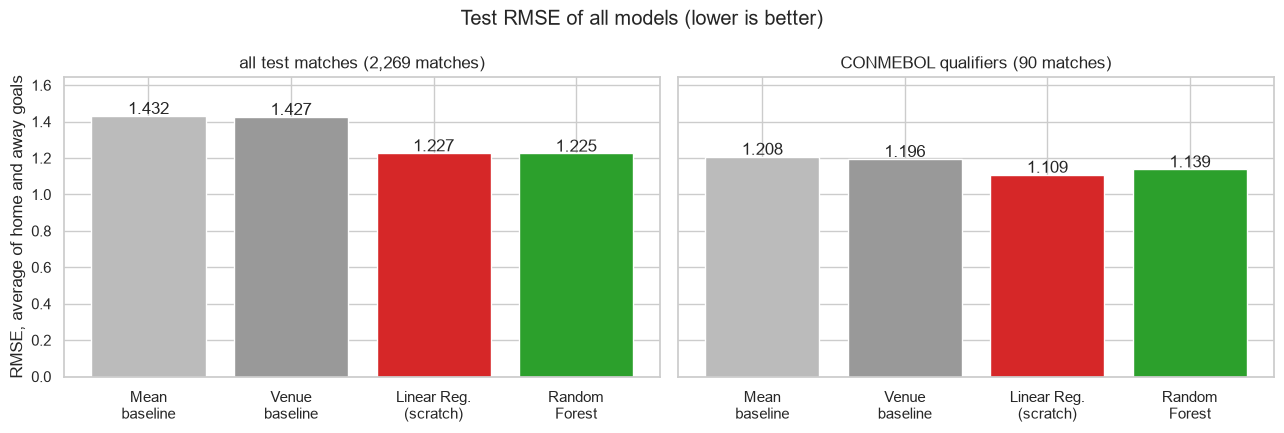

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), sharey=True)
top = results.xs(both_target, level="target")["RMSE"].max() * 1.15
order = ["Mean baseline", "Venue baseline", LR, RF]
colors = ["#bbbbbb", "#999999", "tab:red", "tab:green"]
for ax, set_name in zip(axes, ["all test matches", "CONMEBOL qualifiers"]):
    res = results.xs(set_name, level="test set").xs(both_target, level="target")
    vals = res.loc[order, "RMSE"]
    ax.bar(range(len(order)), vals, color=colors)
    ax.set_xticks(range(len(order)), ["Mean\nbaseline", "Venue\nbaseline", "Linear Reg.\n(scratch)", "Random\nForest"])
    for k, v in enumerate(vals):
        ax.text(k, v + 0.01, f"{v:.3f}", ha="center")
    ax.set(title=f"{set_name} ({test_sets[set_name].sum():,} matches)", ylim=(0, top))
axes[0].set_ylabel("RMSE, average of home and away goals")
fig.suptitle("Test RMSE of all models (lower is better)")
plt.tight_layout(); plt.show()

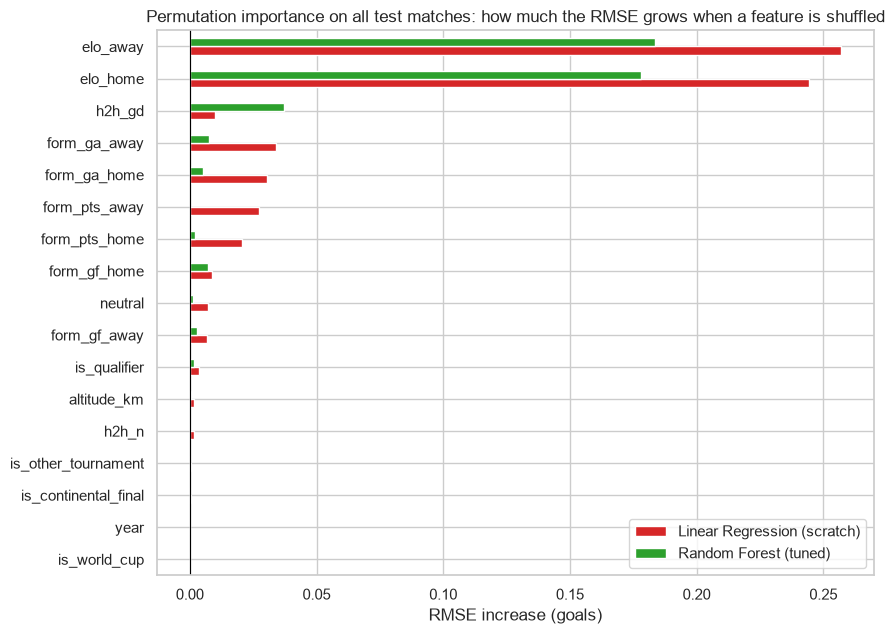

,Linear Regression (scratch),Random Forest (tuned)
elo_away,0.2571,0.1835
elo_home,0.2445,0.1780
form_ga_away,0.0338,0.0075
form_ga_home,0.0304,0.0050
form_pts_away,0.0274,0.0002
form_pts_home,0.0208,0.0019
h2h_gd,0.0097,0.0373
form_gf_home,0.0086,0.0070
neutral,0.0070,0.0013
form_gf_away,0.0066,0.0030


In [66]:
imp_lr = permutation_importance(lr_final, X_test, y_test, n_repeats=10, seed=RANDOM_STATE)
imp_rf = permutation_importance(rf_final, X_test, y_test, n_repeats=10, seed=RANDOM_STATE)
importance = pd.DataFrame({LR: imp_lr["RMSE increase"], RF: imp_rf["RMSE increase"]})
importance = importance.loc[importance.max(axis=1).sort_values().index]

ax = importance.plot(kind="barh", figsize=(9, 6.5), color=["tab:red", "tab:green"])
ax.axvline(0, color="black", lw=0.8)
ax.set(title="Permutation importance on all test matches: how much the RMSE grows when a feature is shuffled",
       xlabel="RMSE increase (goals)")
plt.tight_layout(); plt.show()
importance.sort_values(LR, ascending=False).round(4)

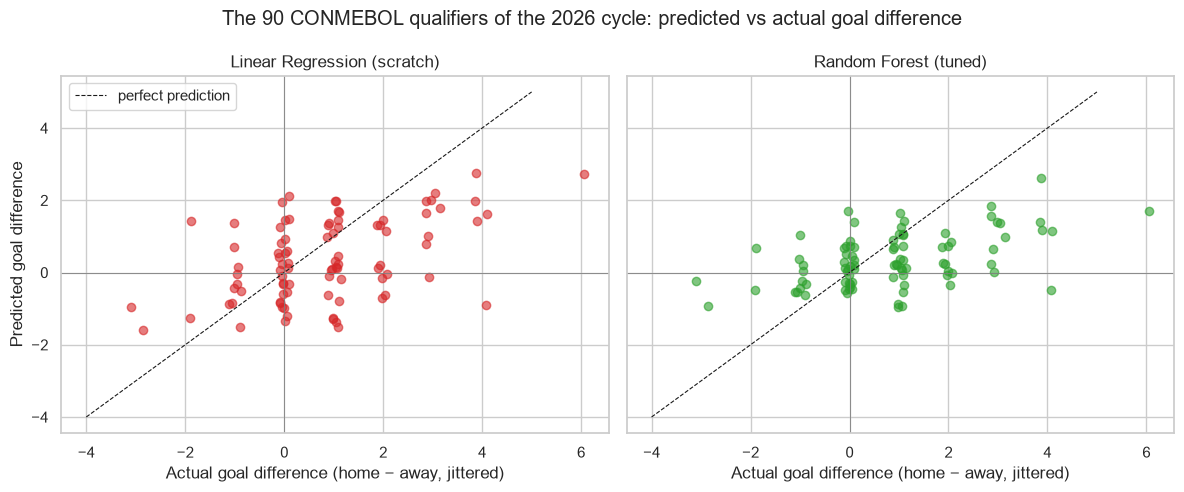

In [67]:
y_con = y_test.to_numpy(dtype=float)[conmebol_test]
rng = np.random.default_rng(RANDOM_STATE)
jitter = rng.uniform(-0.15, 0.15, size=conmebol_test.sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
for ax, (name, model, color) in zip(axes, [(LR, lr_final, "tab:red"), (RF, rf_final, "tab:green")]):
    p = model.predict(X_test[conmebol_test])
    ax.scatter(y_con[:, 0] - y_con[:, 1] + jitter, p[:, 0] - p[:, 1], alpha=0.6, color=color)
    ax.plot([-4, 5], [-4, 5], "k--", lw=0.8, label="perfect prediction")
    ax.axhline(0, color="grey", lw=0.6); ax.axvline(0, color="grey", lw=0.6)
    ax.set(title=name, xlabel="Actual goal difference (home − away, jittered)")
axes[0].set_ylabel("Predicted goal difference")
axes[0].legend(loc="upper left")
fig.suptitle("The 90 CONMEBOL qualifiers of the 2026 cycle: predicted vs actual goal difference")
plt.tight_layout(); plt.show()

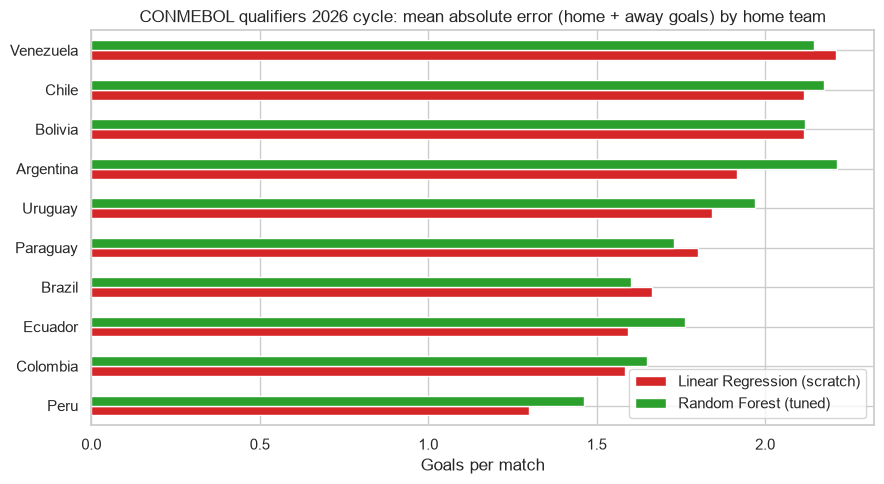

,Linear Regression (scratch),Random Forest (tuned)
home team,,
Peru,1.30,1.46
Colombia,1.59,1.65
Ecuador,1.59,1.76
Brazil,1.67,1.60
Paraguay,1.80,1.73
Uruguay,1.84,1.97
Argentina,1.92,2.21
Bolivia,2.12,2.12
Chile,2.12,2.18


In [68]:
abs_err = lambda model: np.abs(model.predict(X_test[conmebol_test]) - y_con).sum(axis=1)
team_err = pd.DataFrame({"home team": test_df.loc[conmebol_test, "home_team"].to_numpy(),
                         LR: abs_err(lr_final), RF: abs_err(rf_final)})
per_team = team_err.groupby("home team")[[LR, RF]].mean().sort_values(LR)
ax = per_team.plot(kind="barh", figsize=(9, 5), color=["tab:red", "tab:green"])
ax.set(title="CONMEBOL qualifiers 2026 cycle: mean absolute error (home + away goals) by home team",
       xlabel="Goals per match", ylabel="")
plt.tight_layout(); plt.show()
per_team.round(2)

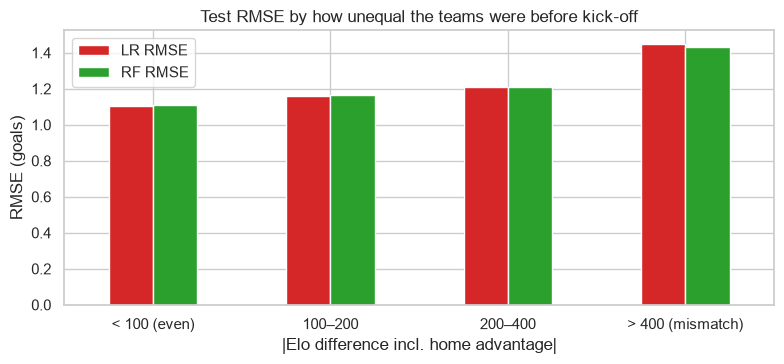

In [69]:
ax = by_gap[["LR RMSE", "RF RMSE"]].plot(kind="bar", rot=0, figsize=(8, 3.8), color=["tab:red", "tab:green"])
ax.set(title="Test RMSE by how unequal the teams were before kick-off", xlabel="|Elo difference incl. home advantage|",
       ylabel="RMSE (goals)")
plt.tight_layout(); plt.show()

### 11.1 Observations

- **Test RMSE (first chart).** Both models clearly beat the baselines on all test matches and are equal to each other; on the CONMEBOL qualifiers the linear model has the lowest bar, but the bootstrap in 10.2 shows that this gap is within the noise of 90 matches.
- **Permutation importance.** The two Elo ratings dominate both models. Altitude hardly matters to either model (0.0016 for the linear model, 0.0003 for the forest), which fits the large errors for Bolivia's matches in El Alto (9.4): the models learned almost nothing from the few high-altitude venues in the training data. `year` and the World Cup flag are not used at all.
- **Predicted vs actual goal difference (90 CONMEBOL qualifiers).** Both clouds are much flatter than the diagonal: neither model predicts big wins or clear away wins, and the forest's predictions are squeezed together even more (spread 0.73 against 1.11 for the linear model). That is typical for models fitted with a squared error — they predict the expected value, and the expected value of a football match is rarely a big win.
- **Errors per home team.** For the linear model the largest errors are in the home matches of Venezuela, Chile and Bolivia (2.1–2.2 goals per match); for the forest Argentina is the worst (2.21), followed by Chile and Venezuela — its cautious predictions under-rate a dominant team (10.4). The smallest error is for Peru (1.30 for the linear model). The linear model has the smaller error for 6 of the 10 teams, the forest for 3 (Brazil, Paraguay, Venezuela), and Bolivia is a tie.
- **RMSE by strength gap.** Both models are most accurate for even matches and least accurate for big mismatches, where scores are high and unpredictable; the forest is only ahead in the mismatch group.

In [70]:
# Guard: every number quoted in 11.1 is recomputed here.
check_quoted({
    "importance altitude LR": (0.0016, importance.loc["altitude_km", LR], 0.00005),
    "importance altitude RF": (0.0003, importance.loc["altitude_km", RF], 0.00005),
    "importance year (both, max)": (0.0, importance.loc["year"].abs().max(), 0.00005),
    "importance World Cup flag (both, max)": (0.0, importance.loc["is_world_cup"].abs().max(), 0.00005),
    "per team: LR's largest 3 errors are Venezuela, Chile, Bolivia": (1, int(set(per_team[LR].nlargest(3).index) == {"Venezuela", "Chile", "Bolivia"}), 0),
    "per team: lowest of LR's largest 3": (2.1, per_team[LR].nlargest(3).min(), 0.05),
    "per team: highest of LR's largest 3": (2.2, per_team[LR].max(), 0.05),
    "per team: RF's worst team is Argentina": (1, int(per_team[RF].idxmax() == "Argentina"), 0),
    "per team: RF Argentina error": (2.21, per_team.loc["Argentina", RF], 0.005),
    "per team: RF's 2nd and 3rd are Chile, Venezuela": (1, int(list(per_team[RF].nlargest(3).index[1:]) == ["Chile", "Venezuela"]), 0),
    "per team: Peru LR": (1.30, per_team.loc["Peru", LR], 0.005),
    "per team: smallest error is Peru (LR)": (1, int(per_team[LR].idxmin() == "Peru"), 0),
    "teams where LR is better": (6, int((per_team[LR] < per_team[RF] - 0.005).sum()), 0),
    "teams where RF is better": (3, int((per_team[RF] < per_team[LR] - 0.005).sum()), 0),
    "RF better for Brazil, Paraguay, Venezuela": (1, int(set(per_team.index[per_team[RF] < per_team[LR] - 0.005]) == {"Brazil", "Paraguay", "Venezuela"}), 0),
    "Bolivia tie": (1, int(abs(per_team.loc["Bolivia", LR] - per_team.loc["Bolivia", RF]) <= 0.005), 0),
})

,typed,computed,ok
quoted in the text,,,
importance altitude LR,0.0016,0.0016,True
importance altitude RF,0.0003,0.0003,True
"importance year (both, max)",0.0000,0.0000,True
"importance World Cup flag (both, max)",0.0000,0.0000,True
"per team: LR's largest 3 errors are Venezuela, Chile, Bolivia",1.0000,1.0000,True
per team: lowest of LR's largest 3,2.1000,2.1153,True
per team: highest of LR's largest 3,2.2000,2.2104,True
per team: RF's worst team is Argentina,1.0000,1.0000,True
per team: RF Argentina error,2.2100,2.2126,True


In [71]:
# Guard: every number quoted in 10.4 is recomputed here ("Run All" fails if text and results drift apart).
sb = scoreboard
bt = bootstrap_table
def boot(set_name, a, b, metric="RMSE"):
    return bt.loc[(set_name, f"{a} − {b}", metric)]
mismatch = by_gap.loc["> 400 (mismatch)"]
even = by_gap.loc["< 100 (even)"]
pred_con_lr, pred_con_rf = lr_final.predict(X_test[conmebol_test]), rf_final.predict(X_test[conmebol_test])
check_quoted({
    "all: RMSE LR": (1.227, sb.loc[LR, "all: RMSE"], 0.0005), "all: RMSE RF": (1.225, sb.loc[RF, "all: RMSE"], 0.0005),
    "all: MAE LR": (0.934, sb.loc[LR, "all: MAE"], 0.0005), "all: MAE RF": (0.936, sb.loc[RF, "all: MAE"], 0.0005),
    "all: R² home LR": (0.29, sb.loc[LR, "all: R² home"], 0.005), "all: R² home RF": (0.29, sb.loc[RF, "all: R² home"], 0.005),
    "all: R² away LR": (0.23, sb.loc[LR, "all: R² away"], 0.005), "all: R² away RF": (0.24, sb.loc[RF, "all: R² away"], 0.005),
    "all: W/D/L LR": (59.9, sb.loc[LR, "all: W/D/L %"], 0.05), "all: W/D/L RF": (59.5, sb.loc[RF, "all: W/D/L %"], 0.05),
    "all: LR−RF interval low": (-0.010, boot("all test matches", LR, RF)["ci_low"], 0.0005),
    "all: LR−RF interval high": (0.012, boot("all test matches", LR, RF)["ci_high"], 0.0005),
    "all: LR better in % of samples": (38, boot("all test matches", LR, RF)["A better in % of samples"], 0.5),
    "all: gain over venue baseline, LR": (-0.20, boot("all test matches", LR, "Venue baseline")["difference"], 0.005),
    "all: gain over venue baseline, RF": (-0.20, boot("all test matches", RF, "Venue baseline")["difference"], 0.005),
    "all: baseline intervals exclude 0": (1, int(boot("all test matches", LR, "Venue baseline")["ci_high"] < 0
                                                  and boot("all test matches", RF, "Venue baseline")["ci_high"] < 0), 0),
    "CONMEBOL: RMSE LR": (1.109, sb.loc[LR, "CONMEBOL: RMSE"], 0.0005), "CONMEBOL: RMSE RF": (1.139, sb.loc[RF, "CONMEBOL: RMSE"], 0.0005),
    "CONMEBOL: MAE LR": (0.907, sb.loc[LR, "CONMEBOL: MAE"], 0.0005), "CONMEBOL: MAE RF": (0.942, sb.loc[RF, "CONMEBOL: MAE"], 0.0005),
    "CONMEBOL: LR better in % of samples": (93, boot("CONMEBOL qualifiers", LR, RF)["A better in % of samples"], 0.5),
    "CONMEBOL: LR−RF interval low": (-0.067, boot("CONMEBOL qualifiers", LR, RF)["ci_low"], 0.0005),
    "CONMEBOL: LR−RF interval high": (0.010, boot("CONMEBOL qualifiers", LR, RF)["ci_high"], 0.0005),
    "CONMEBOL: LR−venue interval low": (-0.167, boot("CONMEBOL qualifiers", LR, "Venue baseline")["ci_low"], 0.0005),
    "CONMEBOL: LR−venue interval high": (0.004, boot("CONMEBOL qualifiers", LR, "Venue baseline")["ci_high"], 0.0005),
    "CONMEBOL: LR−venue better %": (97, boot("CONMEBOL qualifiers", LR, "Venue baseline")["A better in % of samples"], 0.5),
    "CONMEBOL: RF−venue interval low": (-0.116, boot("CONMEBOL qualifiers", RF, "Venue baseline")["ci_low"], 0.0005),
    "CONMEBOL: RF−venue interval high": (0.009, boot("CONMEBOL qualifiers", RF, "Venue baseline")["ci_high"], 0.0005),
    "CONMEBOL: RF−venue better %": (95, boot("CONMEBOL qualifiers", RF, "Venue baseline")["A better in % of samples"], 0.5),
    "CONMEBOL: W/D/L RF": (52.2, sb.loc[RF, "CONMEBOL: W/D/L %"], 0.05), "CONMEBOL: W/D/L LR": (50.0, sb.loc[LR, "CONMEBOL: W/D/L %"], 0.05),
    "CONMEBOL: W/D/L always home": (54.4, sb.loc["Venue baseline", "CONMEBOL: W/D/L %"], 0.05),
    "importance elo_away LR": (0.26, importance.loc["elo_away", LR], 0.005), "importance elo_away RF": (0.18, importance.loc["elo_away", RF], 0.005),
    "importance elo_home LR": (0.24, importance.loc["elo_home", LR], 0.005), "importance elo_home RF": (0.18, importance.loc["elo_home", RF], 0.005),
    "Elo features are the top 2 for both": (1, int(set(importance[LR].nlargest(2).index) == set(importance[RF].nlargest(2).index) == {"elo_home", "elo_away"}), 0),
    "correlation home predictions": (0.93, lr_vs_rf["correlation of the predicted home goals"], 0.005),
    "correlation away predictions": (0.90, lr_vs_rf["correlation of the predicted away goals"], 0.005),
    "same predicted result %": (92, 100 * lr_vs_rf["same predicted result (W/D/L)"], 0.5),
    "mismatches: matches": (418, mismatch["matches"], 0),
    "mismatches: RF RMSE": (1.430, mismatch["RF RMSE"], 0.0005), "mismatches: LR RMSE": (1.451, mismatch["LR RMSE"], 0.0005),
    "mismatches: LR negative predictions": (112, mismatch["LR negative predictions"], 0),
    "only group where RF is better": (1, int((by_gap["RF − LR"] < 0).sum()), 0),
    "even: LR RMSE": (1.104, even["LR RMSE"], 0.0005), "even: RF RMSE": (1.109, even["RF RMSE"], 0.0005),
    "CONMEBOL spread of predicted GD, RF": (0.73, np.std(pred_con_rf[:, 0] - pred_con_rf[:, 1]), 0.005),
    "CONMEBOL spread of predicted GD, LR": (1.11, np.std(pred_con_lr[:, 0] - pred_con_lr[:, 1]), 0.005),
    "CONMEBOL spread of actual GD": (1.59, np.std(y_con[:, 0] - y_con[:, 1]), 0.005),
    "Argentina: LR error lower by": (0.30, per_team.loc["Argentina", RF] - per_team.loc["Argentina", LR], 0.005),
    "CONMEBOL away goals predicted RF": (1.12, pred_con_rf[:, 1].mean(), 0.005),
    "CONMEBOL away goals predicted LR": (0.98, pred_con_lr[:, 1].mean(), 0.005),
    "importance h2h_gd RF": (0.037, importance.loc["h2h_gd", RF], 0.0005), "importance h2h_gd LR": (0.010, importance.loc["h2h_gd", LR], 0.0005),
    "importance form_ga_away LR": (0.034, importance.loc["form_ga_away", LR], 0.0005), "importance form_ga_home LR": (0.030, importance.loc["form_ga_home", LR], 0.0005),
    "importance form_ga_away RF": (0.008, importance.loc["form_ga_away", RF], 0.0005), "importance form_ga_home RF": (0.005, importance.loc["form_ga_home", RF], 0.0005),
    "forest draw band (OOB = in-sample = 0)": (0, lr_vs_rf["forest draw band: out-of-bag"] + lr_vs_rf["forest draw band: in-sample"], 0),
})

,typed,computed,ok
quoted in the text,,,
all: RMSE LR,1.227,1.2271,True
all: RMSE RF,1.225,1.2254,True
all: MAE LR,0.934,0.9338,True
all: MAE RF,0.936,0.9361,True
all: R² home LR,0.290,0.2914,True
all: R² home RF,0.290,0.2892,True
all: R² away LR,0.230,0.2319,True
all: R² away RF,0.240,0.2394,True
all: W/D/L LR,59.900,59.9383,True
